# **Automated Analysis Pipeline Notebook**
## Diabetes Prediction and Automated Analysis

**Student Name:** Jeremy Childress

---

**Dataset:** Pima Indians Diabetes Database (NIH–NIDDK)

**Description:** This dataset contains diagnostic measurements from women aged 21 years or older of Pima Indian heritage. The binary prediction task is to classify whether a patient has diabetes based on the available predictor variables.

**Notebook Purpose:** Demonstrate data exploration, inferential statistics, and automated machine learning workflows, including data ingestion, missing-value handling, preprocessing, model training, and evaluation.

**Note:** This dataset is used for instructional and demonstration purposes only.

### Overview

This notebook runs an automated analysis of the Pima diabetes data from start to finish. It loads the file, cleans and checks it, explores the variables, runs a few inferential tests, and then trains and evaluates classifiers for the diabetes outcome. A lot of the steps are written to adapt on their own, so they check something about the data or a setting first and then decide what to do. I walk through how that works below, then add four modifications of my own (marked **Modification 1 to 4** in the cell titles) and interpret what changed.

**Pipeline stages**

1. **Settings.** One cell holds the values that drive the decisions later on (seed, alpha, outcome name, analysis goal, cutoffs), so they are not scattered through the code.
2. **Ingestion.** Upload a file and let the extension decide which pandas reader to use.
3. **Inspection.** Look at rows, columns, types, and summary statistics.
4. **Validation and missing data.** Recode impossible zeros as missing and report which predictors need imputation.
5. **Exploratory analysis.** Correlations (Pearson, Spearman, Phi-K) and a set of plots.
6. **Inferential statistics.** One-sample t-test, Welch's t-test, one-way ANOVA, chi-square, and my automated test selection.
7. **ML setup.** Encode the outcome, split 70/30 with stratification, and check class balance and the analysis goal.
8. **Models.** Logistic regression, decision tree, and a random forest I added, each inside a sklearn Pipeline so imputation and scaling are learned from training data only.
9. **Evaluation.** Confusion matrices, a metrics table, ROC curves, a cutoff chosen by cross-validation, and decision tree feature importance.

### How the conditional logic drives the workflow

Most of the "automation" here is just if/elif/else checks placed before each step. These are the ones that actually change what the pipeline does.

- **File type.** The upload cell reads the extension and picks `read_csv` (with delimiter sniffing), `read_excel`, `read_json`, or `read_parquet`. Anything else stops with an error instead of guessing.
- **Impossible zeros.** Zeros in Glucose, D_BP, Skin_Thickness, Insulin, and BMI become NaN, but only `if variable in df.columns`, so the cell doesn't break on a dataset without those columns. This list is the one place that needs knowledge of the data.
- **Missing values.** The next cell finds numeric predictors on its own (everything numeric except the outcome) and only prints an imputation table if something is actually missing.
- **Outcome coding.** If the outcome is already 0/1 nothing happens. If it uses text labels that are in `label_map` they get mapped. Anything else raises an error, since the ML code assumes 0/1.
- **Guard checks.** The tests and the ML split refuse to run if there are fewer than two groups, too few observations, zero variance, non-numeric predictors, or a non-binary outcome. The chi-square cell also warns when expected counts are under 5.
- **Model-specific preprocessing.** In the model loop, scaling is added only `if isinstance(classifier, LogisticRegression)`. Trees don't care about scale, so they get imputation only.
- **Cutoff and tuning.** The decision tree is tuned with GridSearchCV on a chosen metric, and the logistic regression cutoff is picked from cross-validated ROC results instead of the default 0.5.

My modifications add three more decision points of this kind. Modification 1 picks a test based on skewness. Modification 2 sets the tuning metric and cutoff rule from the user's goal. Modification 3 turns on class weighting when the outcome is imbalanced.

### Methods in the notebook

**Inferential.** A one-sample t-test (is mean BMI different from 30), Welch's two-sample t-test (BMI by outcome, without assuming equal variances), a one-way ANOVA of glucose by outcome, and a chi-square test of independence between outcome and having more than 10 pregnancies. With only two groups the ANOVA is basically the same question as a t-test (F is about t squared). It's there to show the general multi-group version.

**Supervised ML.** Logistic regression (liblinear solver, scaled inputs) and a decision tree tuned over depth, leaf size, max leaf nodes, and class weight with 5-fold stratified CV. I added a random forest as a third model for comparison.

## **Settings**

I pulled the values that drive decisions into one cell. Changing `ANALYSIS_GOAL` to `"balanced"` reruns the ML part the way the original notebook did. `"screening"` favors catching diabetes cases.

In [1]:
# @title **Pipeline settings (used by the modified cells)**
import numpy as np
import pandas as pd

RANDOM_SEED = 42        # used for sampling, splitting, CV, and models
ALPHA = 0.05            # significance level for the tests
TARGET = "Outcome"      # binary outcome, coded 0/1

ANALYSIS_GOAL = "screening"   # "screening" (prioritize recall) or "balanced" (F1 / Youden)
TARGET_RECALL = 0.80          # minimum CV sensitivity for the screening cutoff
SKEW_CUTOFF = 1.0             # |skewness| above this switches to a nonparametric test
MIN_CLASS_SHARE = 0.40        # if the smaller class is below this share, weight the classes

np.random.seed(RANDOM_SEED)
print(f"Goal: {ANALYSIS_GOAL} | alpha: {ALPHA} | seed: {RANDOM_SEED}")

Goal: screening | alpha: 0.05 | seed: 42


## **Data Ingestion and Inspection**

Upload `Example Dataset_Diabetes.csv` when the button appears. The cell checks the extension and chooses the reader. After that, the next few cells are just a first look at the data before anything gets changed.

In [2]:
# @title **Upload your dataset**

from google.colab import files
import pandas as pd
import io
from pathlib import Path

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one data file.")

filename = next(iter(uploaded))
extension = Path(filename).suffix.lower()
file_data = io.BytesIO(uploaded[filename])

if extension in [".csv", ".tsv", ".txt"]:
    # Automatically detect the delimiter.
    df = pd.read_csv(file_data, sep=None, engine="python")

elif extension in [".xlsx", ".xls"]:
    # Load the first worksheet.
    df = pd.read_excel(file_data)

elif extension == ".json":
    df = pd.read_json(file_data)

elif extension == ".parquet":
    df = pd.read_parquet(file_data)

else:
    raise ValueError(
        f"'{extension}' files require a different reader. "
        "Supported formats: CSV, TSV, TXT, XLSX, XLS, JSON, and Parquet."
    )

print(f"Successfully loaded: {filename}")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

display(df.head())

Saving Example Dataset_Diabetes.csv to Example Dataset_Diabetes.csv
Successfully loaded: Example Dataset_Diabetes.csv
Rows: 768 | Columns: 9


,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# @title **View first 10 rows of data**

df.head(10) # CHANGE NUMBER TO INCREASE OR DECREASE THE NUMBER OF ROWS

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [4]:
# @title **View a list of all variables**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
attribute_list = list(df.columns)
print("Variables in the dataset:")
print("")
print(attribute_list)

Variables in the dataset:

['Pregnancies', 'Glucose', 'D_BP', 'Skin_Thickness', 'Insulin', 'BMI', 'Pedigree', 'Age', 'Outcome']


In [5]:
# @title **View the number of rows and columns in the dataset**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
print("Number of rows and columns:")
print("")
df.shape   # (rows, columns)

Number of rows and columns:



(768, 9)

In [6]:
# @title **View general information about the dataset**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Pregnancies     768 non-null    int64  
 1   Glucose         768 non-null    int64  
 2   D_BP            768 non-null    int64  
 3   Skin_Thickness  768 non-null    int64  
 4   Insulin         768 non-null    int64  
 5   BMI             768 non-null    float64
 6   Pedigree        768 non-null    float64
 7   Age             768 non-null    int64  
 8   Outcome         768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
# @title **Describe the data (and data type) for each variable**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Describe all columns
summary = df.describe(include='all').T

# Replace NaN values with 'NA'
summary = summary.fillna('NA')

# Insert formatted variable name + data type
summary.insert(
    0,
    'Variable',
    [f"<b>{col}</b><br><span style='font-weight:normal; font-size:smaller;'>[{df[col].dtype}]</span>" for col in summary.index]
)

# Reset index to clean up formatting
summary.reset_index(drop=True, inplace=True)

# Format numeric columns to 3 decimal places only
styled_summary = (
    summary.style
    .format(precision=3, na_rep="NA")  # Format numbers to 3 decimals
    .set_table_styles([
        {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-align', 'center')]},
        {'selector': 'td', 'props': [('text-align', 'center')]}
    ])
    .hide(axis='index')  # Remove default row index
)

styled_summary

Variable,count,mean,std,min,25%,50%,75%,max
Pregnancies[int64],768.000,3.845,3.370,0.000,1.000,3.000,6.000,17.000
Glucose[int64],768.000,120.895,31.973,0.000,99.000,117.000,140.250,199.000
D_BP[int64],768.000,69.105,19.356,0.000,62.000,72.000,80.000,122.000
Skin_Thickness[int64],768.000,20.536,15.952,0.000,0.000,23.000,32.000,99.000
Insulin[int64],768.000,79.799,115.244,0.000,0.000,30.500,127.250,846.000
BMI[float64],768.000,31.993,7.884,0.000,27.300,32.000,36.600,67.100
Pedigree[float64],768.000,0.472,0.331,0.078,0.244,0.372,0.626,2.420
Age[int64],768.000,33.241,11.760,21.000,24.000,29.000,41.000,81.000
Outcome[int64],768.000,0.349,0.477,0.000,0.000,0.000,1.000,1.000


## **Validation and Missing Data**

`describe()` above shows minimums of 0 for glucose, blood pressure, skin thickness, insulin, and BMI, which aren't physically possible, so they are treated as missing. Missing values are not filled here. The ML pipelines fill them later with medians learned from the training set only, which avoids leaking information from the test set.

In [8]:
# @title **Identify known impossible values for later imputation**

import numpy as np

variables_to_replace_zeros = [
    'Glucose', 'D_BP', 'Skin_Thickness', 'Insulin', 'BMI'
]

for variable in variables_to_replace_zeros:
    if variable in df.columns:
        df[variable] = df[variable].replace(0, np.nan)

print("Impossible zeros replaced with missing values.")
print("The ML pipeline will impute missing predictors using training data.")

Impossible zeros replaced with missing values.
The ML pipeline will impute missing predictors using training data.


In [9]:
# @title **Automatically identify other missing values in numeric predictors**

target_variable = "Outcome"

# Automatically identify numeric predictors.
numeric_predictors = df.select_dtypes(include="number").columns
numeric_predictors = numeric_predictors.drop(
    target_variable, errors="ignore"
)

# Count missing values.
missing_counts = df[numeric_predictors].isna().sum()
predictors_with_missing = missing_counts[missing_counts > 0]

if predictors_with_missing.empty:
    print("No missing values detected in numeric predictors.")
else:
    print("Predictors requiring imputation:")
    display(predictors_with_missing.rename("Missing values").to_frame())
    print("Block #4 will automatically fill these using training-set medians.")

Predictors requiring imputation:


,Missing values
Glucose,5
D_BP,35
Skin_Thickness,227
Insulin,374
BMI,11


Block #4 will automatically fill these using training-set medians.


In [10]:
# @title **Description of just one variable**

# Define the variable name (this can be dynamic)
variable = 'BMI'  # CHANGE VARIABLE HERE


#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Print the title dynamically
print(f"Quantitative Description of {variable}:")
print("")

# Get the description and round it to 3 decimal places
description = df[variable].describe().round(3)

# Print the rounded description
print(description)

Quantitative Description of BMI:

count    757.000
mean      32.457
std        6.925
min       18.200
25%       27.500
50%       32.300
75%       36.600
max       67.100
Name: BMI, dtype: float64


In [11]:
# @title **Number of responses and missing values for each variable**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Count non-null and missing responses
response_counts = df.count()
missing_counts = df.isnull().sum()

# Combine into one DataFrame
df_count = pd.DataFrame({
    'Variable': response_counts.index,
    '# of Responses': response_counts.values,
    '# Missing': missing_counts.values
})

# Display as styled table: bold headers and center-aligned values
df_count.style.set_table_styles([
    {'selector': 'th', 'props': [('font-weight', 'bold'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('text-align', 'center')]}
])

,Variable,# of Responses,# Missing
0,Pregnancies,768,0
1,Glucose,763,5
2,D_BP,733,35
3,Skin_Thickness,541,227
4,Insulin,394,374
5,BMI,757,11
6,Pedigree,768,0
7,Age,768,0
8,Outcome,768,0


In [12]:
# @title **View 15 random rows of data**
# Changed from np.random.seed() (no seed, different rows every run) to a fixed seed.
df.sample(n=15, random_state=RANDOM_SEED) # CHANGE NUMBER HERE TO INCREASE OR DECREASE NUMBER OF RANDOM ROWS

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
668,6,98.0,58.0,33.0,190.0,34.0,0.430,43,0
324,2,112.0,75.0,32.0,NaN,35.7,0.148,21,0
624,2,108.0,64.0,NaN,NaN,30.8,0.158,21,0
690,8,107.0,80.0,NaN,NaN,24.6,0.856,34,0
473,7,136.0,90.0,NaN,NaN,29.9,0.210,50,0
204,6,103.0,72.0,32.0,190.0,37.7,0.324,55,0
97,1,71.0,48.0,18.0,76.0,20.4,0.323,22,0
336,0,117.0,NaN,NaN,NaN,33.8,0.932,44,0
568,4,154.0,72.0,29.0,126.0,31.3,0.338,37,0
148,5,147.0,78.0,NaN,NaN,33.7,0.218,65,0


In [13]:
# @title **Change a variable's data type (e.g., from integer to category)**

# Choose variable to change
variable_to_change = 'Outcome' # CHANGE THIS VARIABLE
new_data_type = 'category' # CHANGE THIS TO THE NEW DATA TYPE (options include category, int64, float)

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
# Capture original data type
original_dtype = df[variable_to_change].dtype

# Change data type (options include category, float, int64)
df[variable_to_change] = df[variable_to_change].astype(new_data_type)

# Capture new data type
new_dtype = df[variable_to_change].dtype

# Print result dynamically
print(f"'{variable_to_change}' variable changed from {original_dtype} to {new_dtype}")
print("")
print("Note: You can revise the code to change the data type for a different variable.")

'Outcome' variable changed from int64 to category

Note: You can revise the code to change the data type for a different variable.


## **Exploratory Data Analysis**

In [14]:
# @title **Pearson's correlation table**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
df.corr()

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
Pregnancies,1.000000,0.128135,0.214178,0.100239,0.082171,0.021719,-0.033523,0.544341,0.221898
Glucose,0.128135,1.000000,0.223192,0.228043,0.581186,0.232771,0.137246,0.267136,0.494650
D_BP,0.214178,0.223192,1.000000,0.226839,0.098272,0.289230,-0.002805,0.330107,0.170589
Skin_Thickness,0.100239,0.228043,0.226839,1.000000,0.184888,0.648214,0.115016,0.166816,0.259491
Insulin,0.082171,0.581186,0.098272,0.184888,1.000000,0.228050,0.130395,0.220261,0.303454
BMI,0.021719,0.232771,0.289230,0.648214,0.228050,1.000000,0.155382,0.025841,0.313680
Pedigree,-0.033523,0.137246,-0.002805,0.115016,0.130395,0.155382,1.000000,0.033561,0.173844
Age,0.544341,0.267136,0.330107,0.166816,0.220261,0.025841,0.033561,1.000000,0.238356
Outcome,0.221898,0.494650,0.170589,0.259491,0.303454,0.313680,0.173844,0.238356,1.000000


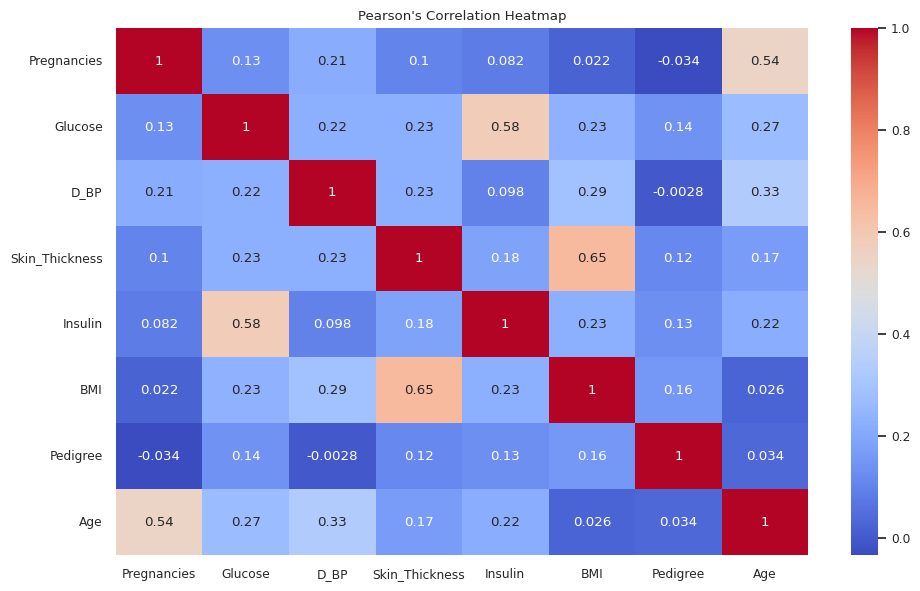

In [15]:
# @title **Pearson's correlation heatmap**

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.set(font_scale=0.8)

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Pearson's Correlation Heatmap")
plt.tight_layout()
plt.show()

In [16]:
# @title **Spearman's Rank correlation table**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
df.corr(method='spearman')

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
Pregnancies,1.000000,0.129547,0.194103,0.086734,0.127859,0.000279,-0.043242,0.607216,0.198689
Glucose,0.129547,1.000000,0.249415,0.229815,0.658813,0.227761,0.090596,0.283315,0.483364
D_BP,0.194103,0.249415,1.000000,0.248017,0.130463,0.299176,0.008511,0.370609,0.177227
Skin_Thickness,0.086734,0.229815,0.248017,1.000000,0.245188,0.685380,0.074979,0.231132,0.265397
Insulin,0.127859,0.658813,0.130463,0.245188,1.000000,0.303515,0.130262,0.267437,0.377300
BMI,0.000279,0.227761,0.299176,0.685380,0.303515,1.000000,0.136138,0.121119,0.309324
Pedigree,-0.043242,0.090596,0.008511,0.074979,0.130262,0.136138,1.000000,0.042909,0.175353
Age,0.607216,0.283315,0.370609,0.231132,0.267437,0.121119,0.042909,1.000000,0.309040
Outcome,0.198689,0.483364,0.177227,0.265397,0.377300,0.309324,0.175353,0.309040,1.000000


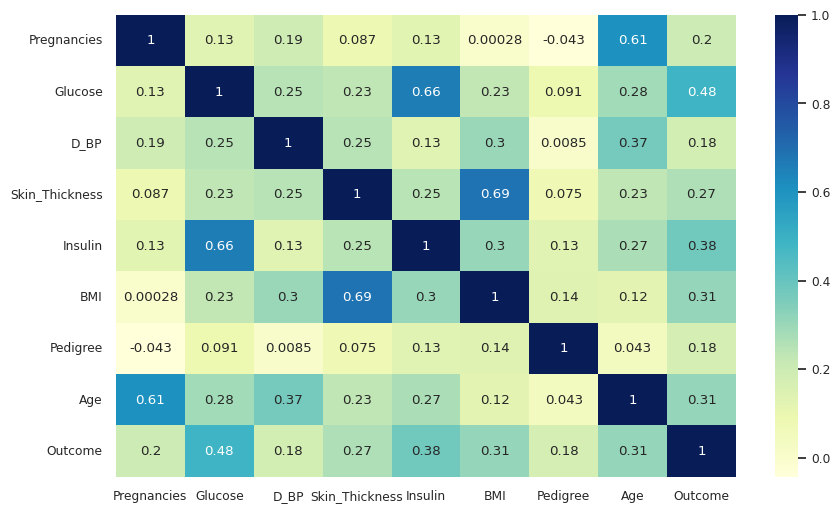

In [17]:
# @title **Spearman's Rank correlation heatmap**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
plt.figure(figsize=(10,6))
sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5
sns.heatmap(df.corr(method='spearman'), annot=True, cmap="YlGnBu");

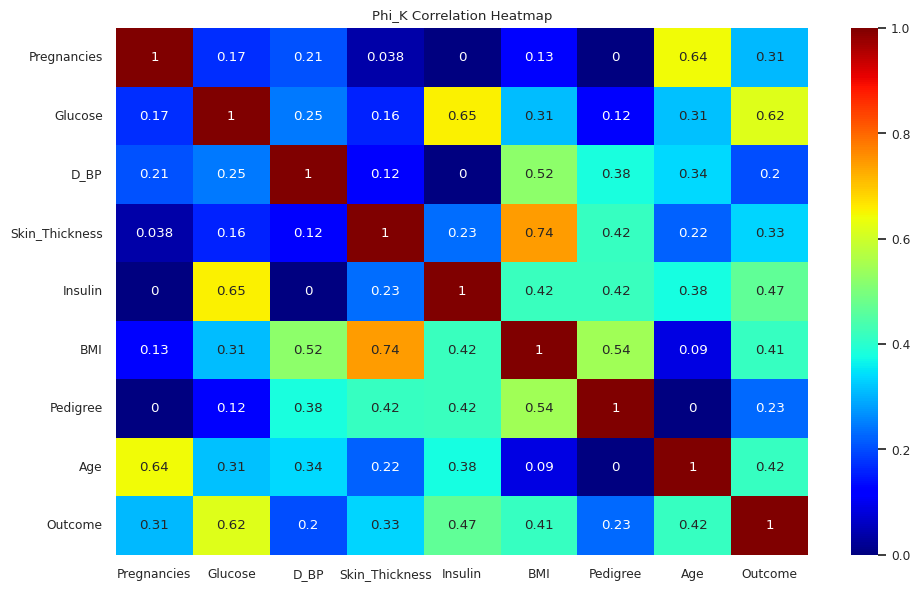

In [18]:
# @title **Phi-K correlation heatmap**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

import os
import sys
import subprocess

# Suppress pip install output
subprocess.run([sys.executable, "-m", "pip", "install", "phik"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

import phik
from phik import resources, report
from phik.report import plot_correlation_matrix
from phik import phik_matrix

# Identify interval (numerical) columns
interval_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Create correlation map using Phi-K
plt.figure(figsize=(10, 6))
sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5

# Compute and plot Phi-K correlation matrix with interval columns specified
phik_corr = df.phik_matrix(interval_cols=interval_cols)
sns.heatmap(phik_corr, annot=True, cmap="jet")

plt.title("Phi_K Correlation Heatmap")
plt.tight_layout()
plt.show()

**What the correlations show.** All three methods agree that glucose has the strongest relationship with the outcome (Pearson r = 0.49, Spearman ρ = 0.48, Phi-K = 0.62). BMI, insulin, and age come next at roughly 0.25 to 0.45 depending on the method. Spearman gives higher values than Pearson for skewed variables like insulin (insulin vs glucose is 0.58 Pearson and 0.66 Spearman), which makes sense since Spearman works on ranks and isn't thrown off by the long right tail. Phi-K values are higher across the board because it picks up nonlinear relationships too and runs from 0 to 1 with no direction. There's also some redundancy among the predictors. BMI and skin thickness (r = 0.65) both measure body fat, and age and pregnancies (r = 0.54) move together for obvious reasons. Pedigree and diastolic BP are only weakly related to the outcome (about 0.17 to 0.23).

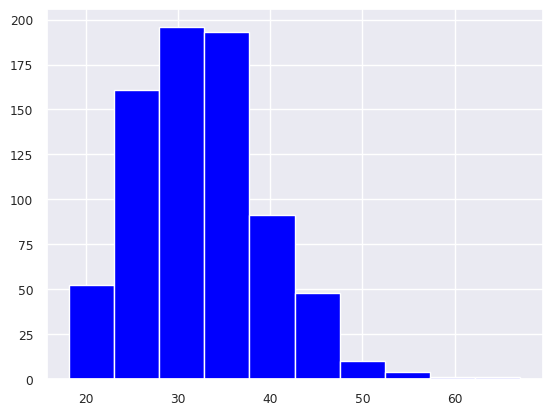

In [19]:
# @title **Example of a histogram**
plt.hist(df['BMI'], color='blue'); # CHANGE VARIABLE HERE

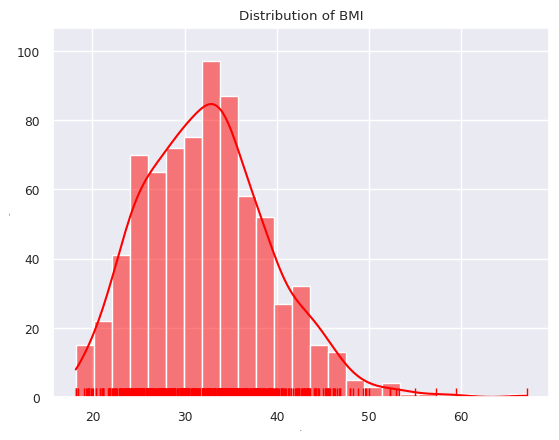

In [20]:
# @title **Example of a distribution plot**

import seaborn as sns
import matplotlib.pyplot as plt

variable = "BMI"

sns.histplot(data=df, x=variable, color="red", kde=True)
sns.rugplot(data=df, x=variable, color="red")

plt.title(f"Distribution of {variable}")
plt.show()

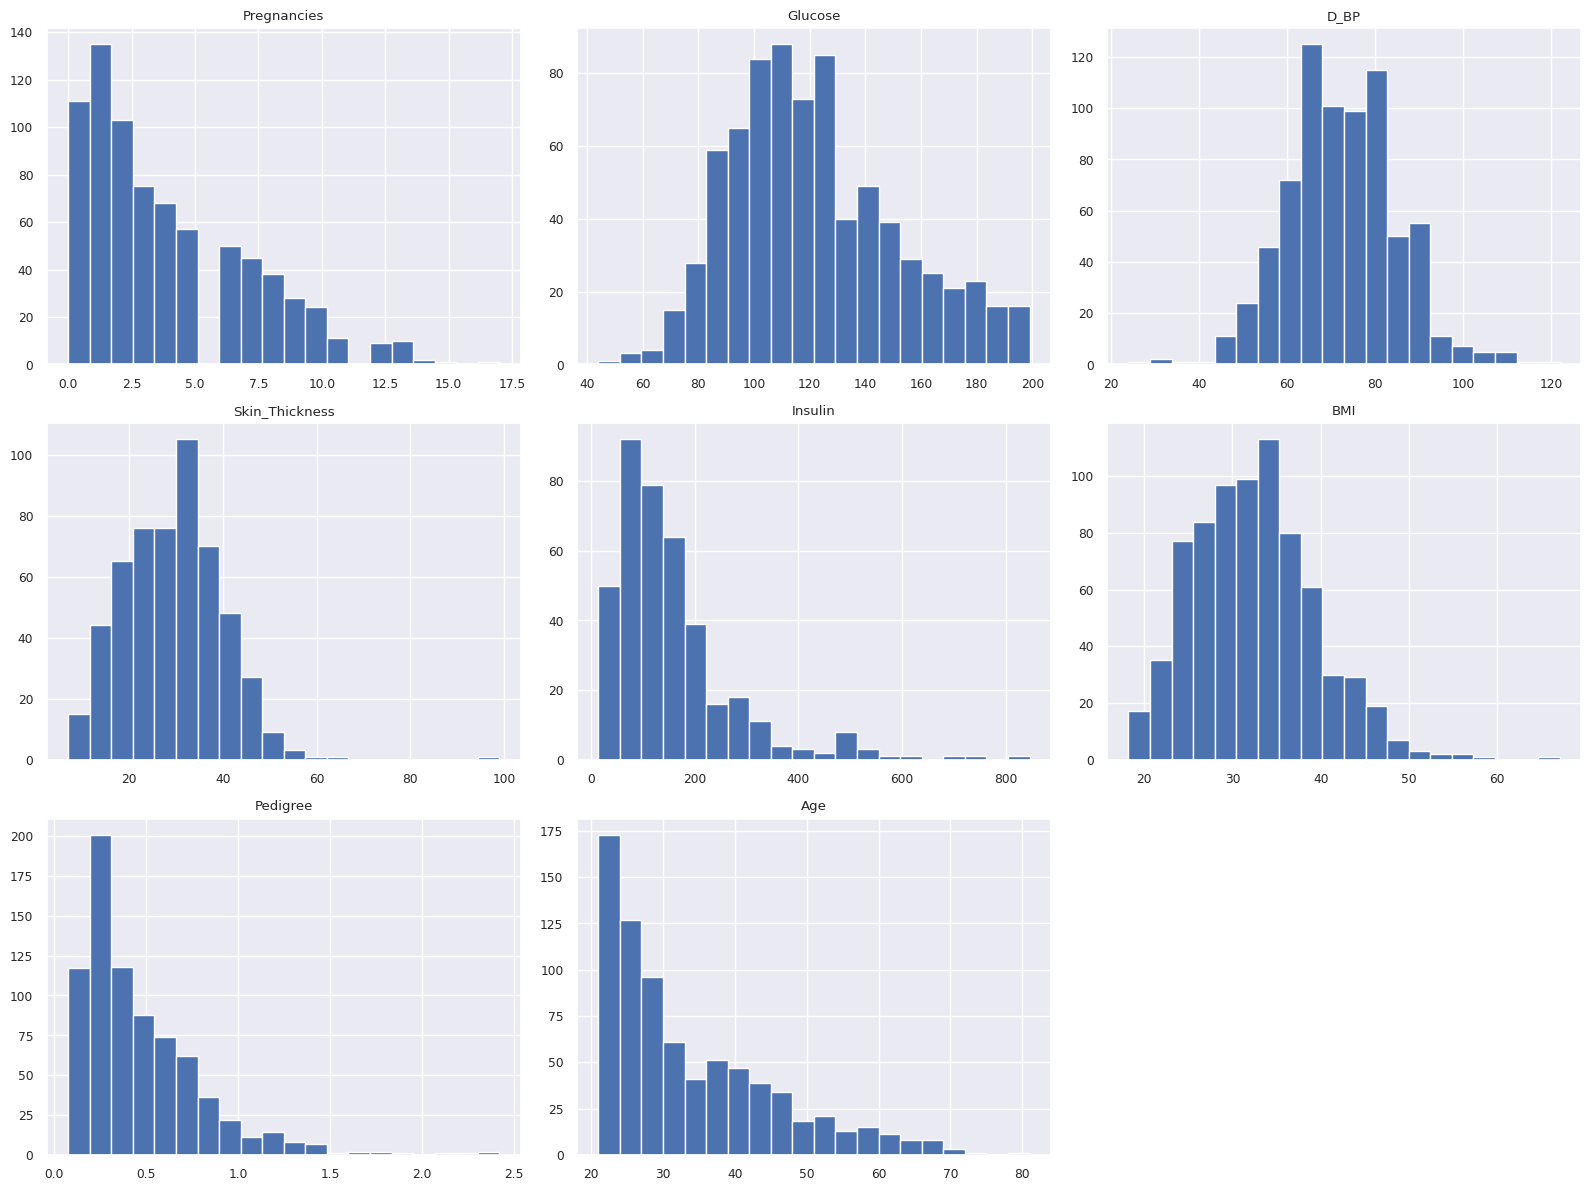

In [21]:
# @title **Generate histograms for all numerical variables**
df.hist(figsize=(16,12), bins=20)
plt.tight_layout()
plt.show()

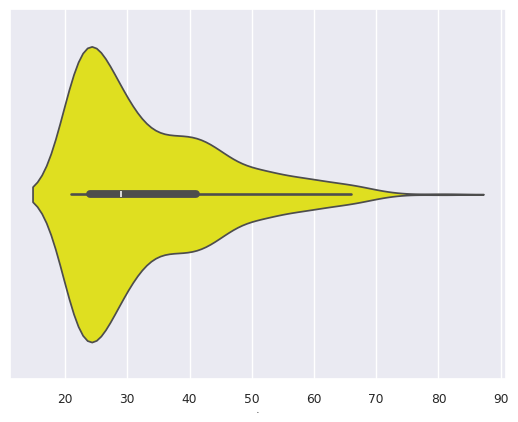

In [22]:
# @title **Example of a violin plot**
sns.violinplot(df['Age'], color='yellow', orient='h'); # CHANGE VARIABLE AND COLOR HERE

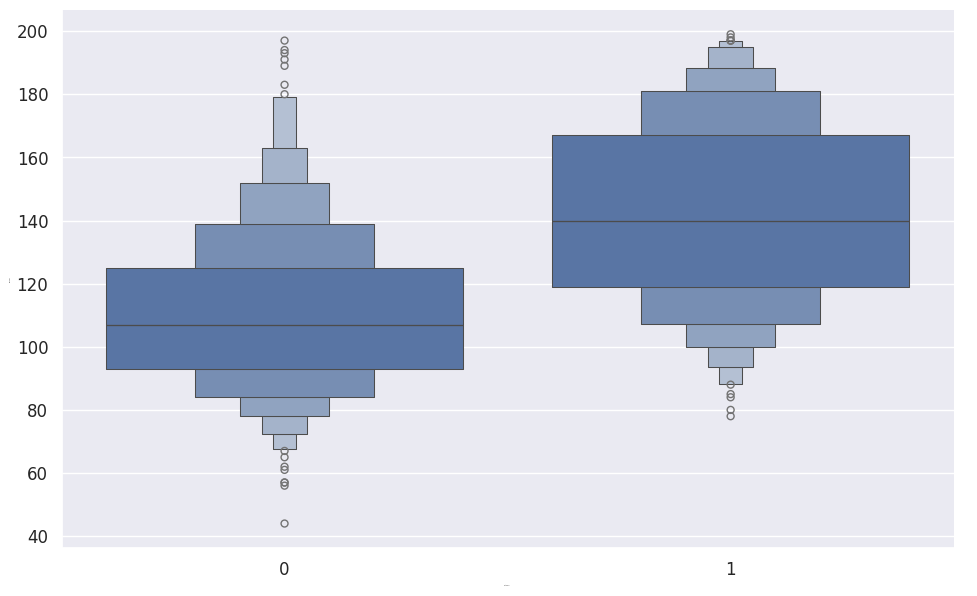

In [23]:
# @title **Example of categorical plot**
# Define the plot variables
x_var = "Outcome"
y_var = "Glucose"

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Create the plot
g = sns.catplot(x=x_var, y=y_var, data=df, kind='boxen', height=6, aspect=1.6, estimator=np.mean);

# Dynamically set axis labels
g.set_axis_labels(x_var, y_var)
g.set_titles("{col_name}")

# Optionally set font size
g.set(xlabel=x_var, ylabel=y_var)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

In [24]:
# @title **Define a function to create a boxplot and histogram combo**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
def histogram_boxplot(feature, figsize=(10,6), bins=None):
    """ Boxplot and histogram combined (horizontal boxplot version)
    feature: 1-d feature array
    figsize: size of fig (default (10,6))
    bins: number of bins (default None / auto)
    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np
    from scipy.stats import norm

    sns.set(font_scale=1)
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (.25, .75)},
        figsize=figsize
    )

    # Horizontal boxplot
    sns.boxplot(x=feature, ax=ax_box2, showmeans=True, color='red')

    # Histogram
    if bins:
        sns.histplot(feature, kde=False, ax=ax_hist2, bins=bins)
    else:
        sns.histplot(feature, kde=False, ax=ax_hist2)

    # Add central tendency lines to histogram
    ax_hist2.axvline(np.mean(feature), color='black', linestyle='--', label='Mean')
    ax_hist2.axvline(np.median(feature), color='green', linestyle='-', label='Median')
    ax_hist2.axvline(feature.mode()[0], color='red', linestyle='dashed', linewidth=1, label='Mode')

    ax_hist2.legend()
    plt.tight_layout()
    plt.show()

print("Function successfully created")

Function successfully created


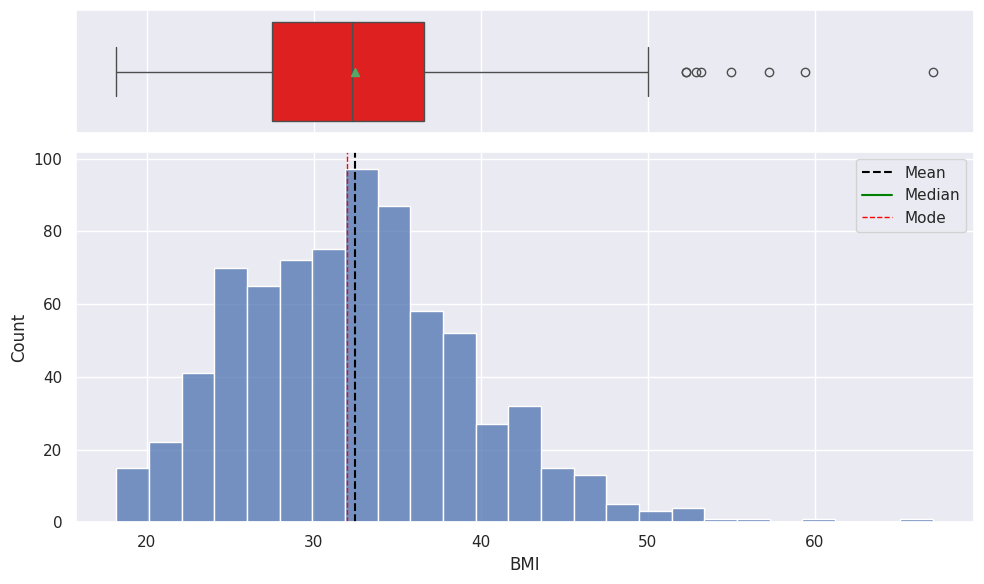

In [25]:
# @title **Example of a combination boxplot and histogram**

histogram_boxplot(df.BMI) # CHANGE THE CONTINUOUS VARIABLE HERE

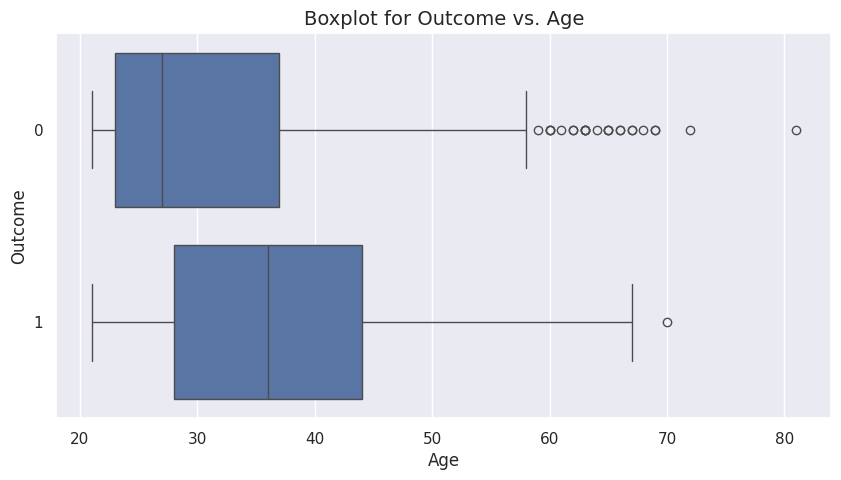

In [26]:
# @title **Example of boxplot with the primary outcome and a continuous variable**

# Define variables
x_var = "Age" # CHANGE VARIABLE HERE
y_var = "Outcome"  # CHANGE VARIABLE HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Plot
plt.figure(figsize=(10, 5))
sns.boxplot(x=x_var, y=y_var, data=df)

# Dynamic labels and title
plt.xlabel(x_var, fontsize=12)
plt.ylabel(y_var, fontsize=12)
plt.title(f'Boxplot for {y_var} vs. {x_var}', fontsize=14)

plt.show()

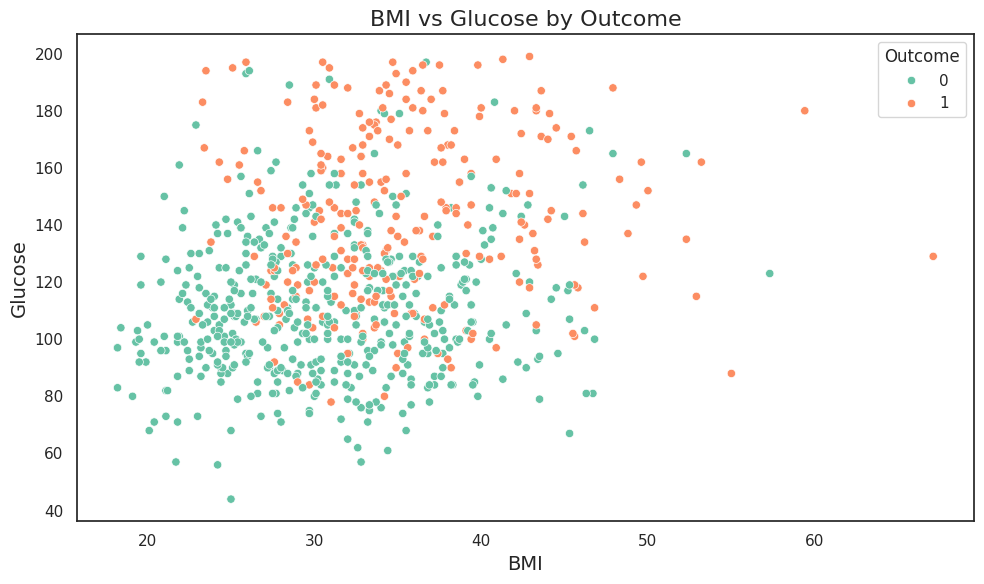

In [27]:
# @title **Example of a scatterplot**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Create the scatterplot
sns.set(style="white")  # Clean background without gridlines
plt.figure(figsize=(10, 6))

# Scatterplot
sns.scatterplot(x='BMI', y='Glucose', hue='Outcome', data=df, palette='Set2')

# Add title and axis labels
plt.title('BMI vs Glucose by Outcome', fontsize=16)
plt.xlabel('BMI', fontsize=14)
plt.ylabel('Glucose', fontsize=14)

# Remove gridlines
plt.grid(False)

# Adjust layout to prevent labels from being cut off
plt.tight_layout()

# Show the plot
plt.show()

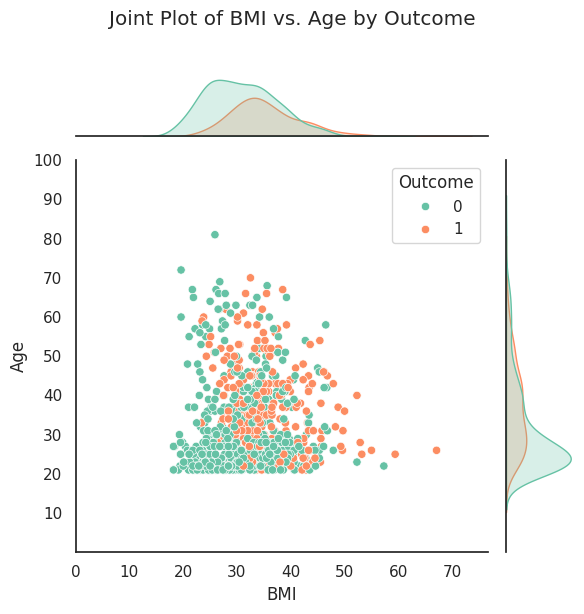

In [28]:
# @title **Example of a joint plot (3 variables)**
g = sns.jointplot(
    x='BMI', # CHANGE VARIABLE HERE
    y='Age', # CHANGE VARIABLE HERE
    hue='Outcome',
    data=df,
    palette='Set2',
    height=6,
)

# Set x-axis and y-axis limits
g.ax_joint.set_xlim(left=0)
g.ax_joint.set_ylim(bottom=0)

# Set y-axis ticks to increase by 10
y_min, y_max = g.ax_joint.get_ylim()
g.ax_joint.set_yticks(np.arange(10, y_max + 10, 10))

# Add title
plt.suptitle("Joint Plot of BMI vs. Age by Outcome", y=1.02)
plt.tight_layout()
plt.show()

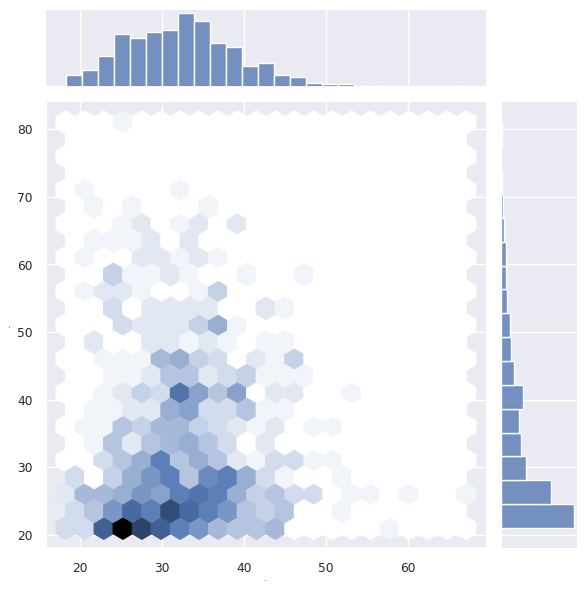

In [29]:
# @title **Example of a joint plot of a different kind (2 variables)**

sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5

sns.jointplot(
    x='BMI', # CHANGE VARIABLE HERE
    y='Age', # CHANGE VARIABLE HERE #---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
    kind='hex',
    data=df,
    palette='Set2',
    height=6  # Smaller and more compact
);

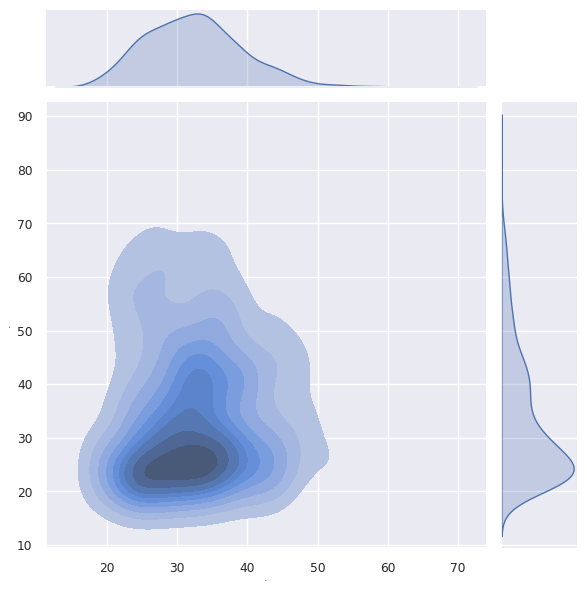

In [30]:
# @title **Another example of a joint plot of a different kind (2 variables)**
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(font_scale=0.8)
plt.rcParams["axes.labelsize"] = 0.5

sns.jointplot(
    x='BMI', # CHANGE VARIABLE HERE
    y='Age', # CHANGE VARIABLE HERE #---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
    kind='kde',
    fill = True,
    data=df,
    palette='Set2',
    height=6  # Smaller and more compact
);

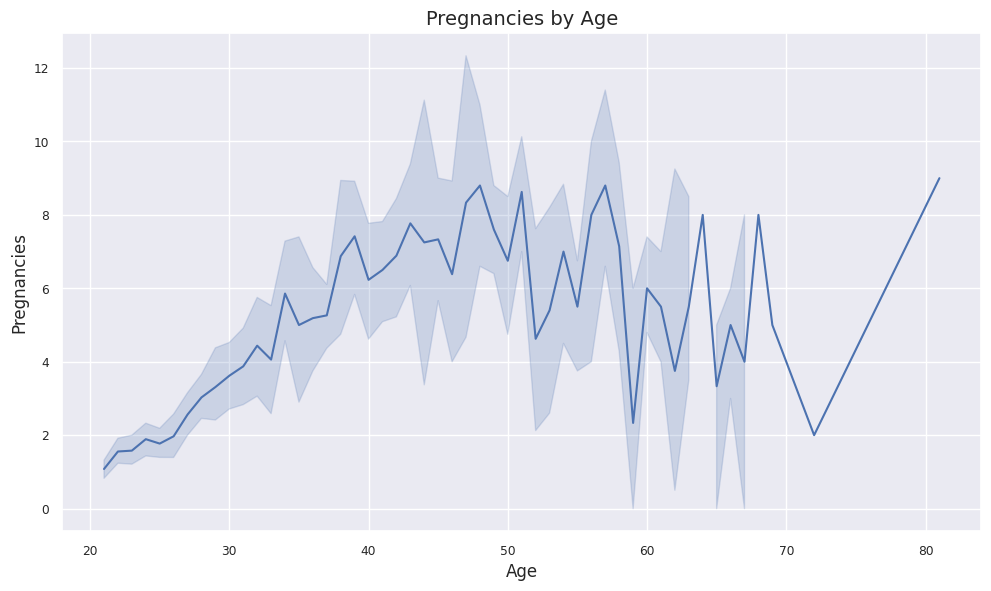

In [31]:
# @title **Example of a line plot**

# Define x and y columns
x_col = 'Age' # CHANGE VARIABLE HERE
y_col = 'Pregnancies' # CHANGE VARIABLE HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#

# Set up figure and axis
fig, ax = plt.subplots(figsize=(10, 6))

# Create lineplot
sns.lineplot(x=x_col, y=y_col, data=df, ax=ax)

# Set axis labels and title explicitly
ax.set_xlabel(x_col, fontsize=12)
ax.set_ylabel(y_col, fontsize=12)
ax.set_title(f'{y_col} by {x_col}', fontsize=14)

# Ensure labels are not cut off
plt.tight_layout()

# Show the plot
plt.show()

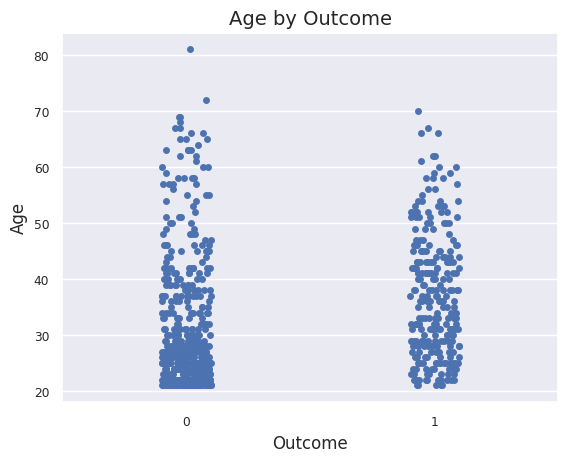

In [32]:
# @title **Example of a strip plot**

# Define axis variables
x_var = "Outcome"  # CHANGE VARIABLE HERE
y_var = "Age"      # CHANGE VARIABLE HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
sns.stripplot(data=df, x=x_var, y=y_var, jitter=True)
plt.xlabel(x_var, fontsize=12)
plt.ylabel(y_var, fontsize=12)
plt.title(f'{y_var} by {x_var}', fontsize=14)
plt.show()

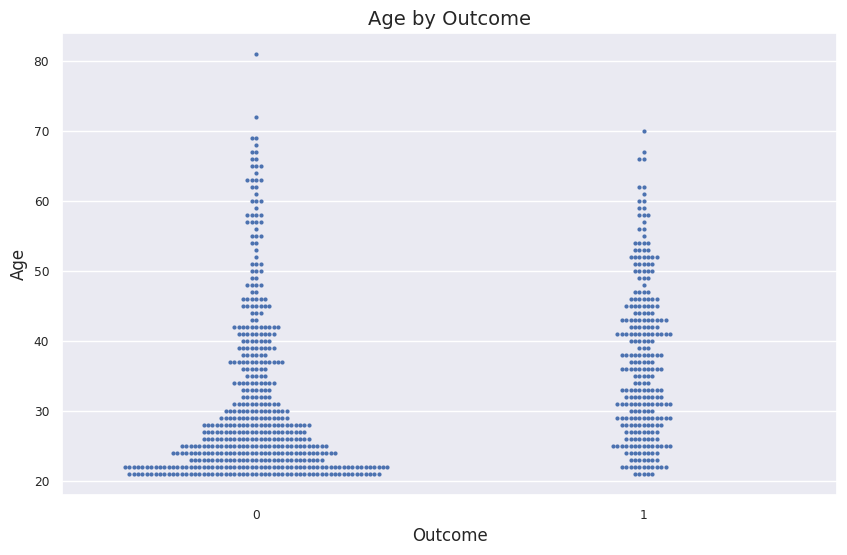

In [33]:
# @title **Example of a swarm plot**

x_var = "Outcome"
y_var = "Age"

plt.figure(figsize=(10, 6))
sns.swarmplot(data=df, x=x_var, y=y_var, size=3)

plt.xlabel(x_var, fontsize=12)
plt.ylabel(y_var, fontsize=12)
plt.title(f'{y_var} by {x_var}', fontsize=14)
plt.show()

**What the plots show.** BMI is roughly bell-shaped once the zeros are gone, with a tail out past 60. Age and insulin are strongly right-skewed. Most patients are in their 20s, and a few insulin values are above 600. In the outcome comparisons, the diabetes group sits higher on glucose (the boxen plot) and is older (median age 36 vs 27 in the strip and swarm plots). The BMI vs glucose scatterplot shows diabetes cases bunching in the upper right, where both are high. The skew in age, insulin, and pedigree matters for the tests below, since it's the reason I added Modification 1.

**Link to other data visualizations: https://seaborn.pydata.org/examples/index.html**

## **Inferential Statistics**

In [34]:
# @title **Import additional inferential statistics libraries**

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------------------------------#
import math
from scipy.stats import ttest_1samp
from scipy.stats import ttest_ind

print("Libraries successfully imported.")

Libraries successfully imported.


In [35]:
# @title **Example of a one-sample t-test**

from scipy.stats import ttest_1samp

variable = "BMI"       # CHANGE VARIABLE HERE
threshold = 30        # CHANGE REFERENCE VALUE HERE
alpha = 0.05          # CHANGE SIGNIFICANCE LEVEL HERE

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude missing observations.
values = df[variable].dropna()

if len(values) < 2 or values.std() == 0:
    raise ValueError(
        "The test requires at least two nonmissing values and nonzero variance."
    )

# Perform a two-sided one-sample t-test.
t_statistic, p_value = ttest_1samp(values, popmean=threshold)

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

if p_value < alpha:
    decision = "Reject the null hypothesis."
    direction = "higher" if t_statistic > 0 else "lower"
    interpretation = (
        f"There is evidence that the population mean {variable} "
        f"is {direction} than {threshold}."
    )
else:
    decision = "Fail to reject the null hypothesis."
    interpretation = (
        f"There is insufficient evidence that the population mean "
        f"{variable} differs from {threshold}."
    )

print(f"Null hypothesis: The population mean {variable} equals {threshold}.")
print(f"Alternative hypothesis: The population mean {variable} differs from {threshold}.")
print(f"\nNonmissing observations: {len(values)}")
print(f"Sample mean: {values.mean():.3f}")
print(f"t-statistic: {t_statistic:.3f}")
print(f"p {formatted_p}")
print(f"Decision: {decision}")
print(f"Interpretation: {interpretation}")

Null hypothesis: The population mean BMI equals 30.
Alternative hypothesis: The population mean BMI differs from 30.

Nonmissing observations: 757
Sample mean: 32.457
t-statistic: 9.764
p < 0.001
Decision: Reject the null hypothesis.
Interpretation: There is evidence that the population mean BMI is higher than 30.


In [36]:
# @title **Independent samples t-test (specific to this dataset)**

from scipy.stats import ttest_ind

variable = "BMI"
group_col = "Outcome"
alpha = 0.05

label_map = {0: "Patients without diabetes", 1: "Patients with diabetes"}

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude observations missing either the measurement or group.
test_data = df[[variable, group_col]].dropna()

if set(test_data[group_col].unique()) != {0, 1}:
    raise ValueError("The group variable must contain both groups, coded 0 and 1.")

# Set a consistent comparison order.
group1 = test_data.loc[test_data[group_col] == 0, variable]
group2 = test_data.loc[test_data[group_col] == 1, variable]

if len(group1) < 2 or len(group2) < 2:
    raise ValueError("Each group requires at least two nonmissing observations.")

if group1.var() == 0 and group2.var() == 0:
    raise ValueError("The test requires variation in at least one group.")

group1_name = label_map[0]
group2_name = label_map[1]

# Two-sided Welch's t-test.
t_statistic, p_value = ttest_ind(group1, group2, equal_var=False)

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

if p_value < alpha:
    decision = "Reject the null hypothesis."
    direction = "higher" if t_statistic > 0 else "lower"
    interpretation = (
        f"There is evidence that the population mean {variable} "
        f"for {group1_name.lower()} is {direction} than "
        f"for {group2_name.lower()}."
    )
else:
    decision = "Fail to reject the null hypothesis."
    interpretation = (
        f"There is insufficient evidence of a difference in population "
        f"mean {variable} between the two groups."
    )

print(f"Null hypothesis: The population mean {variable} is equal between groups.")
print(f"Alternative hypothesis: The population mean {variable} differs between groups.")

print(f"\n{group1_name}: n = {len(group1)}, mean = {group1.mean():.3f}")
print(f"{group2_name}: n = {len(group2)}, mean = {group2.mean():.3f}")
print(f"Mean difference (group 0 − group 1): {group1.mean() - group2.mean():.3f}")

print(f"\nWelch's independent samples t-test:")
print(f"t-statistic: {t_statistic:.3f}")
print(f"p {formatted_p}")
print(f"Decision: {decision}")
print(f"Interpretation: {interpretation}")

Null hypothesis: The population mean BMI is equal between groups.
Alternative hypothesis: The population mean BMI differs between groups.

Patients without diabetes: n = 491, mean = 30.860
Patients with diabetes: n = 266, mean = 35.407
Mean difference (group 0 − group 1): -4.547

Welch's independent samples t-test:
t-statistic: -9.055
p < 0.001
Decision: Reject the null hypothesis.
Interpretation: There is evidence that the population mean BMI for patients without diabetes is lower than for patients with diabetes.


In [37]:
# @title **One-way ANOVA (specific to this dataset)**

import statsmodels.api as sm
from statsmodels.formula.api import ols

variable = "Glucose"
group_col = "Outcome"
alpha = 0.05

label_map = {
    0: "Patients without diabetes",
    1: "Patients with diabetes"
}

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude observations missing the measurement or group.
test_data = df[[variable, group_col]].dropna().copy()

# Use standard column names for the model formula.
test_data.columns = ["measurement", "group"]
test_data["group"] = test_data["group"].astype("category")
test_data["group"] = test_data["group"].cat.remove_unused_categories()

group_summary = (
    test_data.groupby("group", observed=True)["measurement"]
    .agg(["count", "mean", "std"])
)

if len(group_summary) < 2:
    raise ValueError("ANOVA requires at least two groups.")

if (group_summary["count"] < 2).any():
    raise ValueError("Each group requires at least two nonmissing observations.")

if (group_summary["std"] == 0).all():
    raise ValueError("The test requires variation within at least one group.")

# Fit the model and calculate the ANOVA table.
anova_model = ols("measurement ~ C(group)", data=test_data).fit()
anova_table = sm.stats.anova_lm(anova_model, typ=2)

f_stat = anova_table.loc["C(group)", "F"]
p_value = anova_table.loc["C(group)", "PR(>F)"]

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

if p_value < alpha:
    decision = "Reject the null hypothesis."
    interpretation = (
        f"There is evidence that at least two groups differ "
        f"in population mean {variable}."
    )
else:
    decision = "Fail to reject the null hypothesis."
    interpretation = (
        f"There is insufficient evidence of a difference "
        f"in population mean {variable} across groups."
    )

# Apply readable group labels for display.
group_summary.index = [
    label_map.get(group, str(group))
    for group in group_summary.index
]

print(f"Null hypothesis: Population mean {variable} is equal across all groups.")
print(f"Alternative hypothesis: At least one population mean differs.")

print("\nGroup summaries:")
display(group_summary.round(3))

print("\nANOVA table:")
display(anova_table.round(3))

print(f"\nF-statistic: {f_stat:.3f}")
print(f"p {formatted_p}")
print(f"Decision: {decision}")
print(f"Interpretation: {interpretation}")

Null hypothesis: Population mean Glucose is equal across all groups.
Alternative hypothesis: At least one population mean differs.

Group summaries:


,count,mean,std
Patients without diabetes,497,110.644,24.777
Patients with diabetes,266,142.320,29.599



ANOVA table:


,sum_sq,df,F,PR(>F)
C(group),173846.334,1.0,246.518,0.0
Residual,536661.802,761.0,NaN,NaN



F-statistic: 246.518
p < 0.001
Decision: Reject the null hypothesis.
Interpretation: There is evidence that at least two groups differ in population mean Glucose.


In [38]:
# @title **Chi-square test of independence (specific to this dataset)**

import pandas as pd
from scipy.stats import chi2_contingency

group_col = "Outcome"
variable = "Pregnancies"
threshold = 10
alpha = 0.05

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Exclude missing values before creating categories.
test_data = df[[group_col, variable]].dropna().copy()
test_data["Above threshold"] = test_data[variable] > threshold

crosstab = pd.crosstab(
    test_data[group_col],
    test_data["Above threshold"]
)

if crosstab.shape[0] < 2 or crosstab.shape[1] < 2:
    raise ValueError("The test requires at least two observed categories per variable.")

# Run Pearson's chi-square test without continuity correction.
chi2_stat, p_value, dof, expected = chi2_contingency(
    crosstab, correction=False
)

formatted_p = "< 0.001" if p_value < 0.001 else f"= {p_value:.3f}"

print("Observed counts (False = ≤ threshold; True = > threshold):")
display(crosstab)

print("\nExpected counts under independence:")
display(pd.DataFrame(
    expected,
    index=crosstab.index,
    columns=crosstab.columns
).round(3))

print(f"\nNull hypothesis: {group_col} and {variable} > {threshold} are independent.")
print(f"Chi-square statistic: {chi2_stat:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p {formatted_p}")

if (expected < 5).any():
    print(
        "\nSmall expected counts detected. For this 2×2 table, "
        "consider Fisher's exact test before interpreting the chi-square result."
    )

if p_value < alpha:
    print("Decision: Reject the null hypothesis.")
    print(
        f"Interpretation: There is evidence of an association between "
        f"{group_col} and having {variable} > {threshold}, "
        "provided the test assumptions are met."
    )
else:
    print("Decision: Fail to reject the null hypothesis.")
    print(
        f"Interpretation: There is insufficient evidence of an association "
        f"between {group_col} and having {variable} > {threshold}, "
        "provided the test assumptions are met."
    )

Observed counts (False = ≤ threshold; True = > threshold):


Above threshold,False,True
Outcome,,
0,486,14
1,248,20



Expected counts under independence:


Above threshold,False,True
Outcome,,
0,477.865,22.135
1,256.135,11.865



Null hypothesis: Outcome and Pregnancies > 10 are independent.
Chi-square statistic: 8.965
Degrees of freedom: 1
p = 0.003
Decision: Reject the null hypothesis.
Interpretation: There is evidence of an association between Outcome and having Pregnancies > 10, provided the test assumptions are met.


**Interpreting the provided tests.** All four reject the null at α = 0.05.

- **One-sample t-test.** Mean BMI is 32.5 (n = 757), significantly above 30 (t = 9.76, p < 0.001). The average patient in this sample is in the obese range.
- **Welch's t-test.** Mean BMI is 35.4 with diabetes vs 30.9 without, a difference of about 4.5 (t = -9.06, p < 0.001).
- **One-way ANOVA.** Glucose differs by outcome (F = 246.5, p < 0.001). With only two groups this is equivalent to a t-test, and it matches the big glucose gap in the plots.
- **Chi-square.** Having more than 10 pregnancies is associated with diabetes (χ² = 8.97, df = 1, p = 0.003). The threshold of 10 is pretty arbitrary, though, and only a small number of women are above it, so I wouldn't lean on this result much.

### **Modification 1: Automated test selection for every predictor**

The original notebook runs one hand-picked test per variable, and always a t-test for the continuous comparisons. Several predictors here are clearly right-skewed (Insulin, Pedigree, Age), and the t-test compares means, which get pulled around by long tails. So I added a function that checks the skewness of each predictor in both outcome groups and picks the test on its own. If either group has |skewness| > `SKEW_CUTOFF` it uses the Mann-Whitney U test (rank based, no normality assumption). Otherwise it uses Welch's t-test. It loops over every numeric predictor, so it would work the same on a different dataset with a binary outcome.

Because this runs 8 tests at once, I also compare each p-value to a Bonferroni-adjusted alpha (0.05 / 8) to keep the overall false positive rate in check.

In [39]:
# @title **Modification 1: Automatically choose a two-group test for each predictor**
from scipy.stats import ttest_ind, mannwhitneyu, skew

def choose_group_test(group0, group1, skew_cutoff=SKEW_CUTOFF):
    """Use Welch's t-test unless either group is strongly skewed, then use Mann-Whitney U.

    Returns the test name, its statistic, its p-value, and the largest |skewness|.
    """
    largest_skew = max(abs(skew(group0)), abs(skew(group1)))

    if largest_skew > skew_cutoff:
        stat, p = mannwhitneyu(group1, group0, alternative="two-sided")
        return "Mann-Whitney U", stat, p, largest_skew

    stat, p = ttest_ind(group1, group0, equal_var=False)
    return "Welch t-test", stat, p, largest_skew


adjusted_alpha = ALPHA / len(numeric_predictors)   # Bonferroni correction
rows = []

for variable in numeric_predictors:
    data = df[[variable, TARGET]].dropna()
    no_diabetes = data.loc[data[TARGET] == 0, variable]
    diabetes = data.loc[data[TARGET] == 1, variable]

    test_name, stat, p, largest_skew = choose_group_test(no_diabetes, diabetes)

    rows.append({
        "Variable": variable,
        "Median (no diabetes)": no_diabetes.median(),
        "Median (diabetes)": diabetes.median(),
        "Max |skew|": round(largest_skew, 2),
        "Test chosen": test_name,
        "Statistic": round(stat, 2),
        "p-value": p,
        "Significant (Bonferroni)": p < adjusted_alpha,
    })

test_table = pd.DataFrame(rows).sort_values("p-value")
print(f"Bonferroni-adjusted alpha: {adjusted_alpha:.4f}")
display(test_table.style.format({"p-value": "{:.2e}"}).hide(axis="index"))

Bonferroni-adjusted alpha: 0.0063


Variable,Median (no diabetes),Median (diabetes),Max |skew|,Test chosen,Statistic,p-value,Significant (Bonferroni)
Glucose,107.000000,140.000000,0.650000,Welch t-test,14.880000,2.84e-41,True
Age,27.000000,36.000000,1.570000,Mann-Whitney U,92050.000000,1.14e-17,True
BMI,30.100000,34.300000,1.010000,Mann-Whitney U,89731.000000,1.82e-17,True
Insulin,102.500000,169.500000,2.500000,Mann-Whitney U,25109.500000,7.48e-14,True
Skin_Thickness,27.000000,32.000000,1.420000,Mann-Whitney U,43050.000000,6.96e-10,True
Pregnancies,2.000000,4.000000,1.110000,Mann-Whitney U,83015.000000,3.75e-08,True
Pedigree,0.336000,0.449000,2.000000,Mann-Whitney U,81231.000000,1.20e-06,True
D_BP,70.000000,74.500000,0.160000,Welch t-test,4.660000,3.97e-06,True


**Interpreting Modification 1.** The skewness check sent 6 of the 8 predictors to Mann-Whitney U and kept Welch's t-test only for glucose and diastolic BP, which are the two closest to symmetric. BMI barely crossed the cutoff (max |skew| = 1.01, from the diabetes group's tail), so it's a borderline call. Every predictor still differs significantly between groups after the Bonferroni correction (all p < 0.0063). The ordering is the useful part. Glucose is by far the strongest (p ≈ 10⁻⁴¹), followed by age, BMI, and insulin, which lines up with the correlations. Using the right test changed some p-values noticeably. For insulin, Welch gives p ≈ 2.7 × 10⁻⁸, while Mann-Whitney gives p ≈ 7.5 × 10⁻¹⁴. The t-test was being weakened by the extreme insulin values, which is exactly the situation the rank-based test is built for. Because of the large sample, everything comes out significant either way, so the medians in the table are more useful for judging how big each difference actually is.

In [40]:
# @title **Encode outcome labels as 0 and 1 (if needed)**

target_variable = "Outcome"
label_map = {"No Diabetes": 0, "Diabetes": 1}

outcome = df[target_variable]
observed_values = set(outcome.dropna().unique())

if observed_values.issubset({0, 1}):
    print("Outcome is already coded as 0/1.")

elif observed_values.issubset(set(label_map)):
    df[target_variable] = outcome.map(label_map)
    print("Outcome labels converted to 0/1.")

else:
    raise ValueError(
        f"Unexpected outcome values: {observed_values}. "
        "Update label_map to match your dataset."
    )

display(df[target_variable].head(10))

Outcome is already coded as 0/1.


,Outcome
0,1
1,0
2,1
3,0
4,1
5,0
6,1
7,0
8,1
9,1


## **Supervised Machine Learning (Binary Classification)**

**How the ML part works.** The split cell separates predictors from the outcome, drops rows missing the outcome (the outcome is never imputed), checks that predictors are numeric and the outcome is 0/1, then makes a stratified 70/30 split so both sets keep the same ~35% diabetes rate. Every model is wrapped in a sklearn `Pipeline`, so the median imputer and the scaler are fit on the training data and only applied to the test data.

**Logistic regression.** https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

## **Logistic Regression**

In [41]:
# @title **Configure and split data for the automated ML pipeline**

from sklearn.model_selection import train_test_split

target_variable = "Outcome"  # CHANGE FOR YOUR DATASET

# Exclude rows with missing outcomes; do not impute the outcome.
ml_data = df.dropna(subset=[target_variable]).copy()

X = ml_data.drop(columns=[target_variable])
y = ml_data[target_variable]

# This demonstration expects numeric predictors and an outcome coded 0/1.
if set(y.unique()) != {0, 1}:
    raise ValueError("The outcome must contain both classes, coded 0 and 1.")

if not all(pd.api.types.is_numeric_dtype(X[col]) for col in X.columns):
    raise ValueError("This pipeline requires numeric predictors.")

y = y.astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Training observations: 537
Test observations: 231


### **Modification 2: Let the analysis goal set the tuning metric and cutoff**

The original pipeline always optimizes F1 for the tree and picks the logistic regression cutoff with Youden's J (sensitivity + specificity − 1). That treats a missed case and a false alarm as about equally bad. For diabetes screening I don't think that's right. A missed case means someone goes undiagnosed, while a false positive usually just means a follow-up test. So I added `ANALYSIS_GOAL`. For `"screening"`, the tree is tuned on F2 (an F-score that weights recall twice as much as precision) and the cutoff is the highest one that still reaches `TARGET_RECALL` sensitivity in cross-validation. For `"balanced"` it falls back to the original F1 and Youden's J. I used F2 instead of plain recall because tuning on recall alone can pick a tree that calls almost everyone positive.

In [42]:
# @title **Modification 2: Set tuning metric and cutoff rule from the analysis goal**
from sklearn.metrics import make_scorer, fbeta_score

if ANALYSIS_GOAL == "screening":
    scoring_metric = make_scorer(fbeta_score, beta=2)
    scoring_name = "F2"
    threshold_rule = "target_recall"
elif ANALYSIS_GOAL == "balanced":
    scoring_metric = "f1"
    scoring_name = "F1"
    threshold_rule = "youden"
else:
    raise ValueError("ANALYSIS_GOAL must be 'screening' or 'balanced'.")

print(f"Analysis goal: {ANALYSIS_GOAL}")
print(f"Decision tree tuning metric: {scoring_name}")
print(f"Cutoff rule: {threshold_rule}")

Analysis goal: screening
Decision tree tuning metric: F2
Cutoff rule: target_recall


### **Modification 3: Check class balance and weight the classes automatically**

Only about 35% of patients have diabetes, so an unweighted model can do fine on accuracy by leaning toward "no diabetes". This cell checks the smaller class's share of the training data. If it's under `MIN_CLASS_SHARE` (0.40), the logistic regression and random forest use `class_weight="balanced"`, which weights each class inversely to its frequency. If the data were closer to balanced it would leave the weights alone. The tuned decision tree already searches over `class_weight`, so I left that grid as is.

In [43]:
# @title **Modification 3: Turn on class weighting if the outcome is imbalanced**
class_shares = y_train.value_counts(normalize=True).sort_index()
minority_share = class_shares.min()

print("Training class shares:")
print(class_shares.round(3).to_string())

if minority_share < MIN_CLASS_SHARE:
    model_class_weight = "balanced"
    print(f"\nSmaller class is {minority_share:.1%} (< {MIN_CLASS_SHARE:.0%}), so class_weight='balanced'.")
else:
    model_class_weight = None
    print(f"\nClasses are reasonably balanced ({minority_share:.1%}), so no class weighting.")

Training class shares:
Outcome
0    0.652
1    0.348

Smaller class is 34.8% (< 40%), so class_weight='balanced'.


In [44]:
# @title **Define a function to display a confusion matrix**

from sklearn.metrics import confusion_matrix

def make_confusion_matrix(y_actual, y_predict):
    """Display counts and percentages of all evaluated observations."""

    cm = confusion_matrix(y_actual, y_predict, labels=[0, 1])

    if cm.sum() == 0:
        raise ValueError("No observations with labels 0 or 1 to display.")

    cell_names = np.array([
        ["True negative", "False positive"],
        ["False negative", "True positive"]
    ])

    annotations = np.array([
        f"{name}\n{count}\n{count / cm.sum():.2%}"
        for name, count in zip(cell_names.flatten(), cm.flatten())
    ]).reshape(2, 2)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=annotations,
        fmt="",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

print("Function successfully created.")

Function successfully created.


In [45]:
# @title **Build logistic regression with automated preprocessing (uses Modification 3 weights)**

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Learn imputation and scaling from training data only.
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        solver="liblinear",
        class_weight=model_class_weight,   # set by Modification 3
        random_state=RANDOM_SEED
    ))
])

logistic_pipeline.fit(X_train, y_train)

# Apply the fitted preprocessing and model to test data.
y_predict = logistic_pipeline.predict(X_test)
model_score = logistic_pipeline.score(X_test, y_test)

print(f"Test-set accuracy: {model_score:.2%}")
print(
    f"The model correctly classified {model_score:.2%} "
    "of observations in the test set."
)

Test-set accuracy: 76.62%
The model correctly classified 76.62% of observations in the test set.


### **Modification 4: Add a random forest and compare all models on one ROC plot**

The decision tree in this loop is a single unpruned tree, which tends to overfit. A random forest averages many trees grown on bootstrap samples, so it's the natural next model to compare. I added it to the `models` dictionary, so the loop handles it automatically. Since it isn't a `LogisticRegression`, the existing `isinstance` check skips scaling for it, which is what we want. I also added a single ROC plot with all three models so they can be compared directly, instead of only the logistic regression curve.

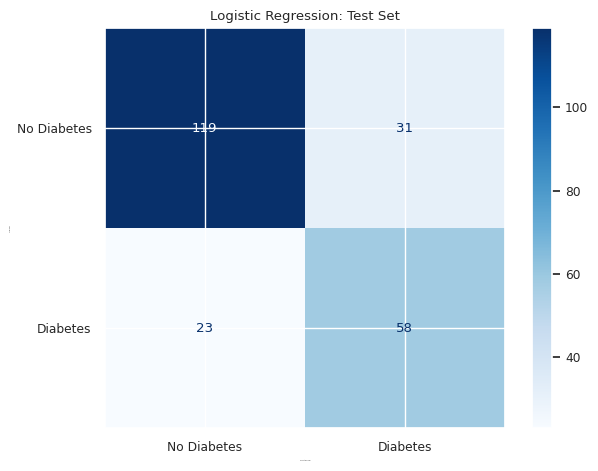

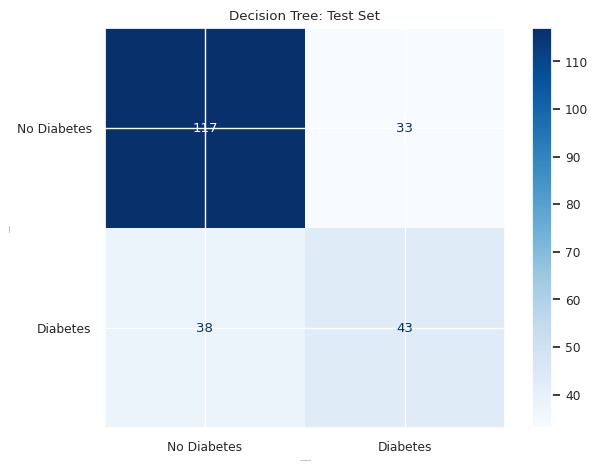

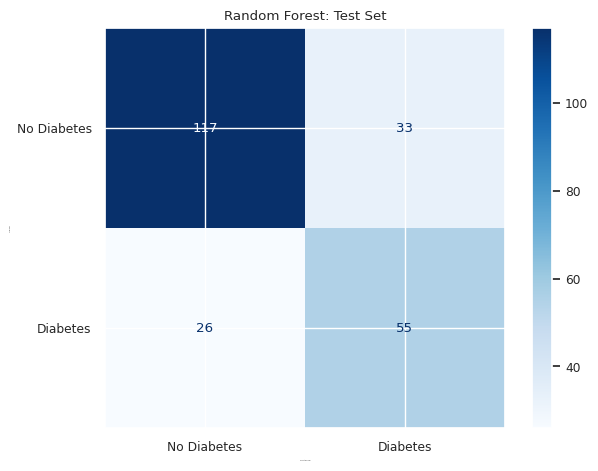

Test-set performance:


,Accuracy,Recall,Precision,F1,ROC AUC
Model,,,,,
Logistic Regression,0.766,0.716,0.652,0.682,0.837
Decision Tree,0.693,0.531,0.566,0.548,0.655
Random Forest,0.745,0.679,0.625,0.651,0.840


In [46]:
# @title **Automatically preprocess, train, and evaluate ML models (Modifications 3 and 4)**

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Define the models to run automatically.
models = {
    "Logistic Regression": LogisticRegression(
        solver="liblinear",
        class_weight=model_class_weight,   # Modification 3
        random_state=RANDOM_SEED
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_SEED
    ),
    # Modification 4: random forest added to the automated comparison
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight=model_class_weight,   # Modification 3
        random_state=RANDOM_SEED
    )
}

trained_pipelines = {}
results = []

for model_name, classifier in models.items():

    # Preprocessing is fitted using training data only.
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    # Apply scaling when appropriate for the model.
    if isinstance(classifier, LogisticRegression):
        steps.append(("scaler", StandardScaler()))

    steps.append(("classifier", classifier))

    pipeline = Pipeline(steps)
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    positive_index = list(pipeline.classes_).index(1)
    probabilities = pipeline.predict_proba(X_test)[:, positive_index]

    trained_pipelines[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=[0, 1],
        display_labels=["No Diabetes", "Diabetes"],
        cmap="Blues"
    )
    plt.title(f"{model_name}: Test Set")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).set_index("Model")

print("Test-set performance:")
display(results_df.round(3))

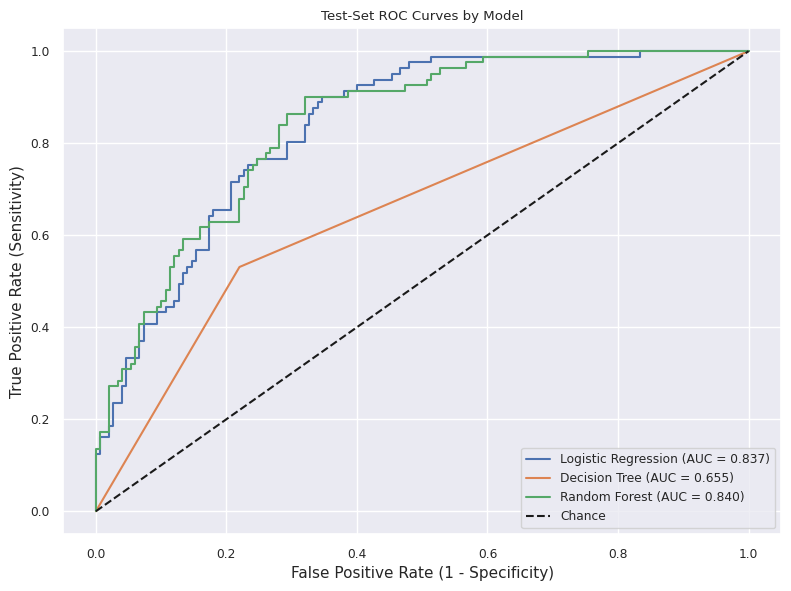

In [47]:
# @title **Modification 4: ROC curves for all models on the test set**
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for model_name, pipeline in trained_pipelines.items():
    positive_index = list(pipeline.classes_).index(1)
    model_probs = pipeline.predict_proba(X_test)[:, positive_index]
    model_fpr, model_tpr, _ = roc_curve(y_test, model_probs)
    model_auc = roc_auc_score(y_test, model_probs)
    plt.plot(model_fpr, model_tpr, label=f"{model_name} (AUC = {model_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=11)
plt.title("Test-Set ROC Curves by Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpreting the model comparison (Modifications 3 and 4).** Turning on class weighting mostly changed the logistic regression. In the original run it had recall 0.531, so it missed almost half the diabetes cases in the test set. With `class_weight="balanced"` recall goes up to 0.716 and F1 from 0.593 to 0.682, with accuracy slightly higher (0.745 to 0.766) and precision only a little lower (0.672 to 0.652). ROC AUC basically didn't move (0.836 to 0.837). That's expected, since weighting changes where the model draws the line, not how well it ranks patients.

The random forest (AUC 0.840) ranks patients about as well as logistic regression, and both are well ahead of the single unpruned decision tree (AUC 0.655). The ROC plot makes that obvious, since the tree's curve sits well below the other two. A random forest isn't really worth its extra complexity here. Logistic regression does just as well and is much easier to explain, which counts for a lot in a clinical setting. The unpruned tree is clearly overfitting. The tuned tree later in the notebook does much better.

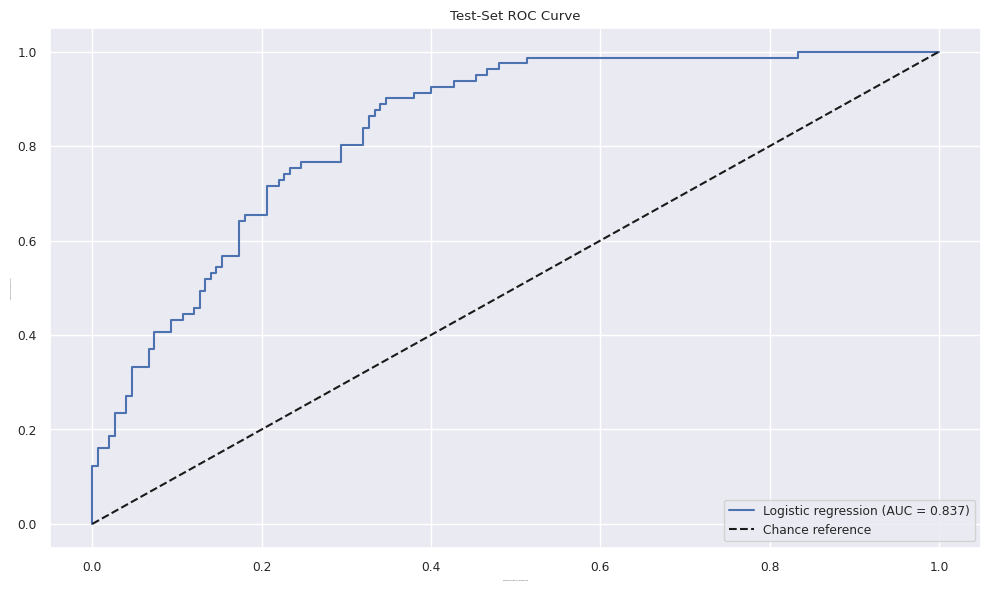

Test-set ROC AUC: 0.837


In [48]:
# @title **ROC curve and AUC for logistic regression**

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

# Predict probabilities for the positive class (1).
positive_index = list(logistic_pipeline.classes_).index(1)
y_probability = logistic_pipeline.predict_proba(X_test)[:, positive_index]

# Calculate test-set ROC AUC and curve.
logit_roc_auc = roc_auc_score(y_test, y_probability)
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {logit_roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance reference")
plt.xlabel("False Positive Rate (1 − Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("Test-Set ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Test-set ROC AUC: {logit_roc_auc:.3f}")

In [49]:
# @title **Select a cutoff using training-set cross-validation (rule set by Modification 2)**

import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_curve

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

# Use the logistic_pipeline defined in the training block.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

if y_train.value_counts().min() < 5:
    raise ValueError("Each training class needs at least 5 observations.")

# Each observation is predicted by a pipeline trained on other folds.
# Imputation and scaling are learned separately within each fold.
cv_probabilities = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)

positive_index = list(logistic_pipeline.classes_).index(1)

fpr, tpr, thresholds = roc_curve(
    y_train,
    cv_probabilities[:, positive_index]
)

# Exclude the infinite threshold representing no positive predictions.
finite = np.isfinite(thresholds)

# Modification 2: the cutoff rule depends on the analysis goal.
if threshold_rule == "target_recall":
    # Highest cutoff that still reaches the target sensitivity in CV.
    meets_target = finite & (tpr >= TARGET_RECALL)
    optimal_threshold = thresholds[meets_target].max()
    criterion = f"highest cutoff with CV sensitivity >= {TARGET_RECALL:.0%}"
else:
    j_scores = tpr[finite] - fpr[finite]
    optimal_threshold = thresholds[finite][np.argmax(j_scores)]
    criterion = "maximum CV sensitivity + specificity - 1 (Youden's J)"

chosen = np.where(thresholds == optimal_threshold)[0][0]
print(f"Selected threshold: {optimal_threshold:.3f}")
print(f"Criterion: {criterion}")
print(f"CV sensitivity at this cutoff: {tpr[chosen]:.3f} | CV specificity: {1 - fpr[chosen]:.3f}")

Selected threshold: 0.414
Criterion: highest cutoff with CV sensitivity >= 80%
CV sensitivity at this cutoff: 0.802 | CV specificity: 0.686


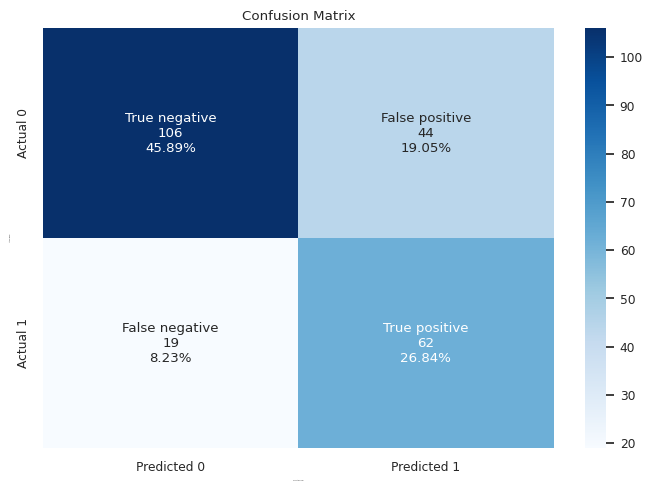

In [50]:
# @title **Make confusion matrix using the selected cutoff**

positive_index = list(logistic_pipeline.classes_).index(1)

test_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, positive_index]

y_pred_ts = (test_probabilities >= optimal_threshold).astype(int)

make_confusion_matrix(y_test, y_pred_ts)

In [51]:
# @title **Compare training and test F1 at the selected cutoff**

from sklearn.metrics import f1_score

positive_index = list(logistic_pipeline.classes_).index(1)

train_probabilities = logistic_pipeline.predict_proba(
    X_train
)[:, positive_index]

test_probabilities = logistic_pipeline.predict_proba(
    X_test
)[:, positive_index]

y_pred_tr = (train_probabilities >= optimal_threshold).astype(int)
y_pred_ts = (test_probabilities >= optimal_threshold).astype(int)

print(f"Selected cutoff: {optimal_threshold:.3f}")
print(f"Training F1: {f1_score(y_train, y_pred_tr, zero_division=0):.3f}")
print(f"Test F1: {f1_score(y_test, y_pred_ts, zero_division=0):.3f}")

Selected cutoff: 0.414
Training F1: 0.677
Test F1: 0.663


In [52]:
# @title **Test-set recall and specificity at the selected cutoff**
from sklearn.metrics import recall_score

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_ts, labels=[0, 1]).ravel()
print(f"Test sensitivity (recall): {tp / (tp + fn):.3f}")
print(f"Test specificity: {tn / (tn + fp):.3f}")
print(f"Missed diabetes cases (false negatives): {fn} of {tp + fn}")

Test sensitivity (recall): 0.765
Test specificity: 0.707
Missed diabetes cases (false negatives): 19 of 81


**Interpreting the cutoff (Modification 2).** Under the screening goal, the cutoff is the highest one that keeps cross-validated sensitivity at 80% or above. That came out to 0.414 (CV sensitivity 0.802, specificity 0.686). On the test set it gives sensitivity 0.765 and specificity 0.707, and it misses 19 of the 81 diabetes cases. For comparison, running the original setup (`ANALYSIS_GOAL = "balanced"`, no class weights) picks 0.443 with Youden's J and misses 35 of 81 (sensitivity 0.568, specificity 0.833). So the screening setup catches 16 more cases in exchange for more false positives. I think that's the right trade for a screening tool, since a false positive leads to a confirmatory test rather than harm. Training and test F1 at the cutoff are close (0.677 vs 0.663), so the logistic model isn't overfitting.

## **Decision Tree**

**DECISION TREE: https://scikit-learn.org/stable/modules/tree.html#**

In [53]:
# @title **Import libraries for decision tree training and evaluation**

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Decision tree libraries imported successfully.")

Decision tree libraries imported successfully.


In [54]:
# @title **Build and tune decision tree using cross-validation (metric set by Modification 2)**

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Modification 2: scoring_metric now comes from ANALYSIS_GOAL (set above).

#---------------------DO NOT CHANGE ANY CODE BELOW THIS LINE---------------------#

dtree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Pipeline parameters require the step name prefix.
parameters = {
    "classifier__max_depth": [2, 4, 6, 8],
    "classifier__min_samples_leaf": [5, 10, 15],
    "classifier__max_leaf_nodes": [5, 10, 15],
    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

if y_train.value_counts().min() < 5:
    raise ValueError("Each training class needs at least 5 observations.")

grid_obj = GridSearchCV(
    estimator=dtree_pipeline,
    param_grid=parameters,
    scoring=scoring_metric,
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid_obj.fit(X_train, y_train)

# Already refitted on the full training set; no additional fit is needed.
dtree = grid_obj.best_estimator_

print("Decision tree pipeline built and tuned.")
print(f"Best mean cross-validation {scoring_name}: {grid_obj.best_score_:.3f}")
print("Selected parameters:")
print(grid_obj.best_params_)

Decision tree pipeline built and tuned.
Best mean cross-validation F2: 0.762
Selected parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 4, 'classifier__max_leaf_nodes': 5, 'classifier__min_samples_leaf': 5}


In [55]:
# @title **Function to calculate accuracy, recall, precision, and F1**

from sklearn import metrics

def get_metrics_score(model, flag=True):
    """Evaluate a fitted classifier on the existing training and test sets."""

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_acc = metrics.accuracy_score(y_train, pred_train)
    test_acc = metrics.accuracy_score(y_test, pred_test)

    train_recall = metrics.recall_score(
        y_train, pred_train, zero_division=0
    )
    test_recall = metrics.recall_score(
        y_test, pred_test, zero_division=0
    )

    train_precision = metrics.precision_score(
        y_train, pred_train, zero_division=0
    )
    test_precision = metrics.precision_score(
        y_test, pred_test, zero_division=0
    )

    train_f1 = metrics.f1_score(y_train, pred_train, zero_division=0)
    test_f1 = metrics.f1_score(y_test, pred_test, zero_division=0)

    score_list = [
        train_acc, test_acc,
        train_recall, test_recall,
        train_precision, test_precision,
        train_f1, test_f1
    ]

    if flag:
        print(f"{'Metric':<12} {'Training':>10} {'Test':>10}")
        for name, train_value, test_value in [
            ("Accuracy", train_acc, test_acc),
            ("Recall", train_recall, test_recall),
            ("Precision", train_precision, test_precision),
            ("F1", train_f1, test_f1)
        ]:
            print(f"{name:<12} {train_value:>10.3f} {test_value:>10.3f}")

    return score_list

print("Metric evaluation function successfully defined.")

Metric evaluation function successfully defined.


In [56]:
# @title **Training vs. test metrics for the tuned tree (uses the function above)**
# This function was defined in the original notebook but never called.
tree_scores = get_metrics_score(dtree)

Metric         Training       Test
Accuracy          0.724      0.714
Recall            0.909      0.827
Precision         0.565      0.563
F1                0.697      0.670


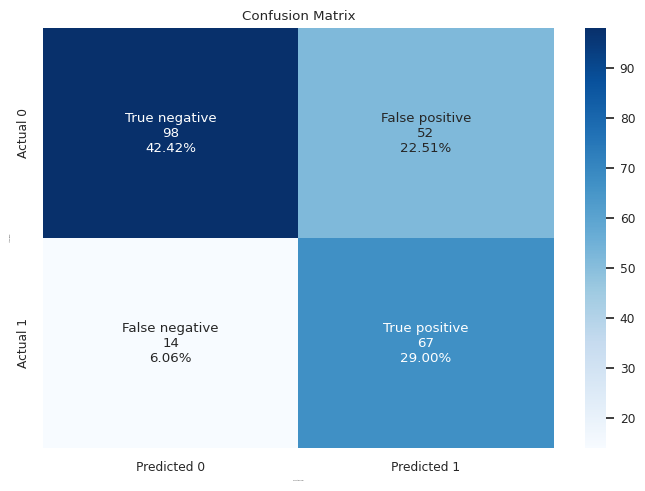

In [57]:
# @title **Display confusion matrix for the tuned decision tree**

y_pred_tree = dtree.predict(X_test)

make_confusion_matrix(y_test, y_pred_tree)

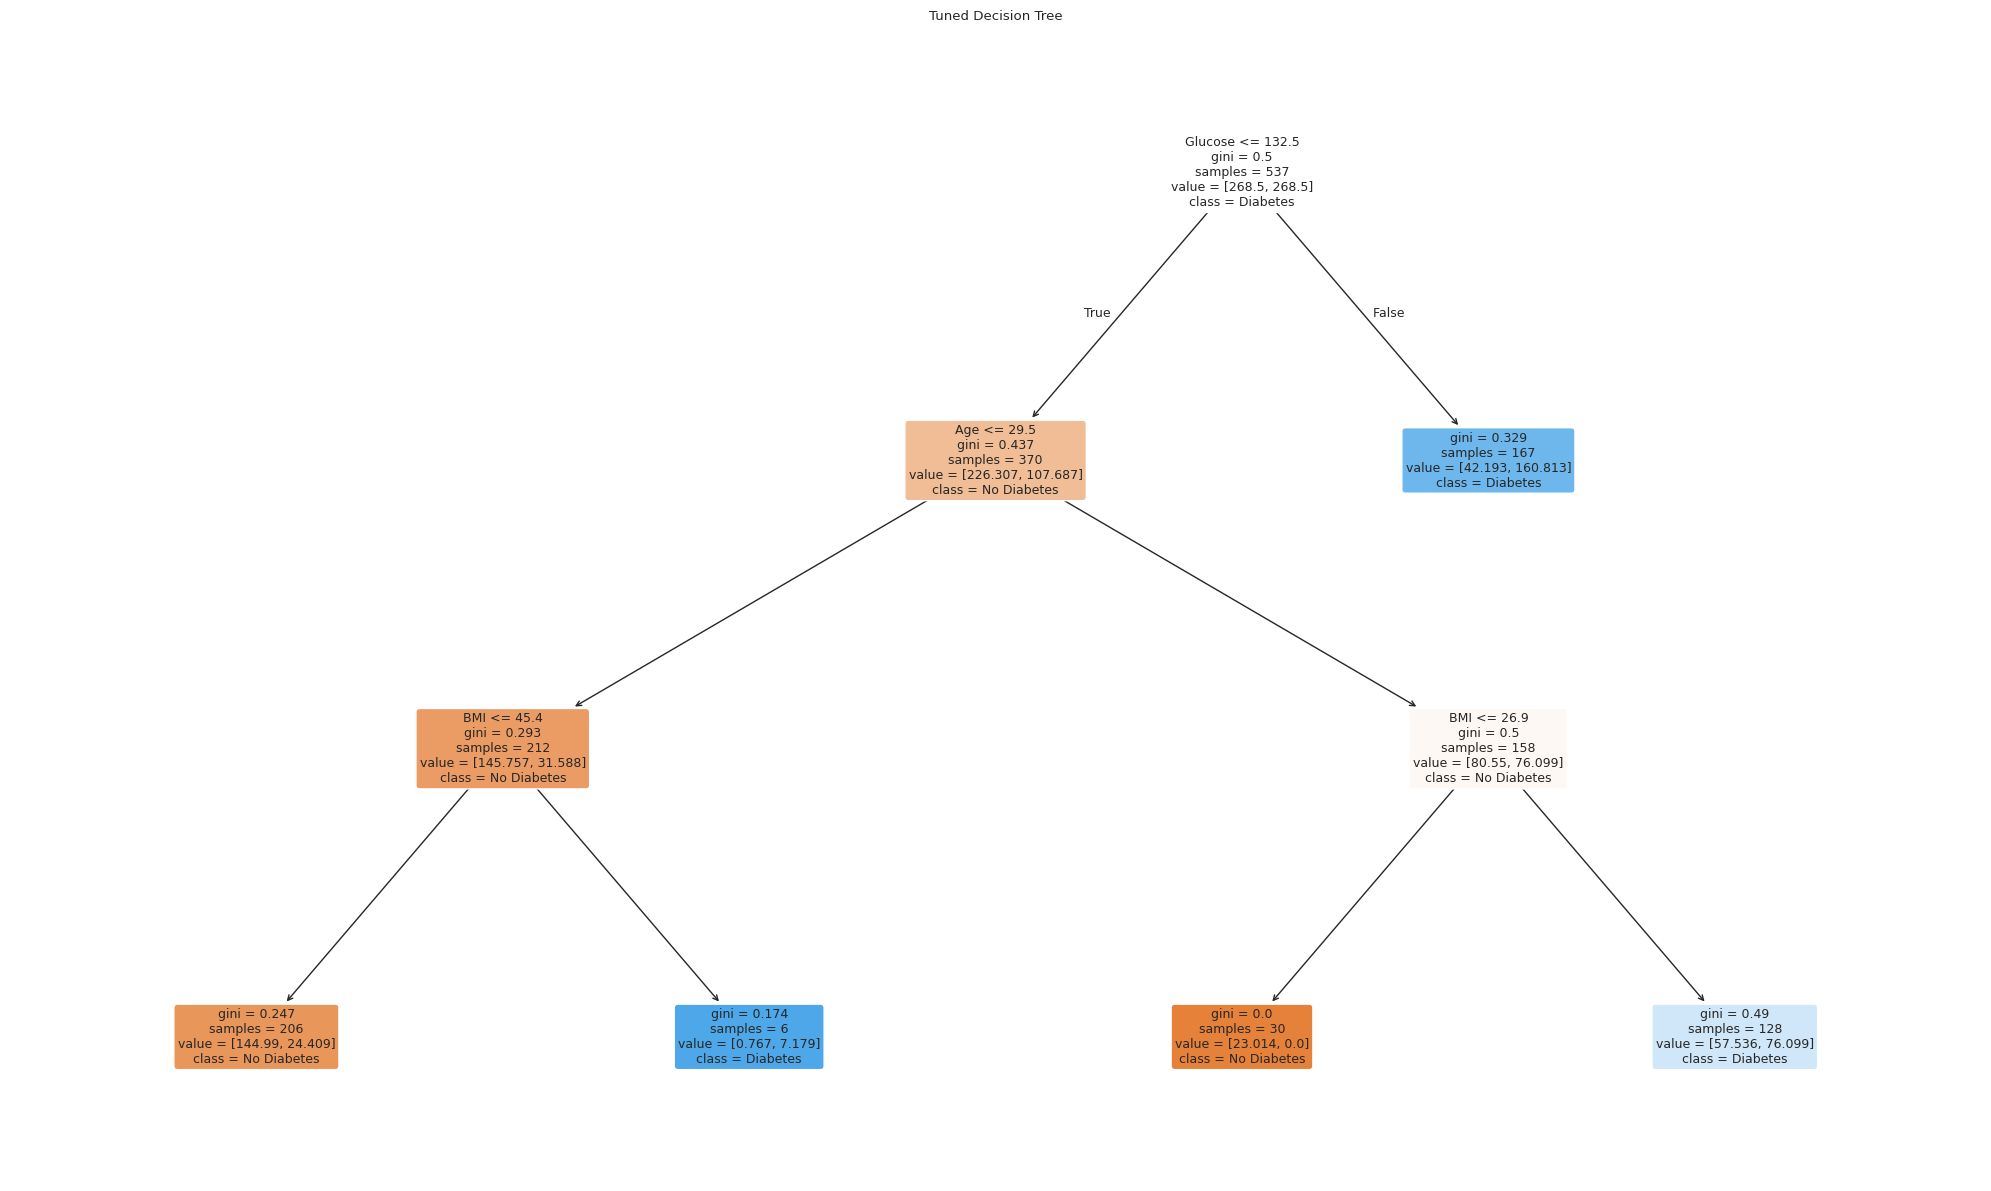

In [58]:
# @title **Show the tuned decision tree**

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

tree_classifier = dtree.named_steps["classifier"]
feature_names = dtree.named_steps["imputer"].get_feature_names_out()

plt.figure(figsize=(20, 12))

plot_tree(
    tree_classifier,
    feature_names=list(feature_names),
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=9,
    node_ids=False
)

plt.title("Tuned Decision Tree")
plt.tight_layout()
plt.show()

In [59]:
# @title **List feature importance from the tuned decision tree**

import pandas as pd

tree_classifier = dtree.named_steps["classifier"]
feature_names = dtree.named_steps["imputer"].get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.reset_index(drop=True).round(3))

,Feature,Importance
0,Glucose,0.599
1,BMI,0.231
2,Age,0.169
3,Pregnancies,0.000
4,Skin_Thickness,0.000
5,D_BP,0.000
6,Insulin,0.000
7,Pedigree,0.000


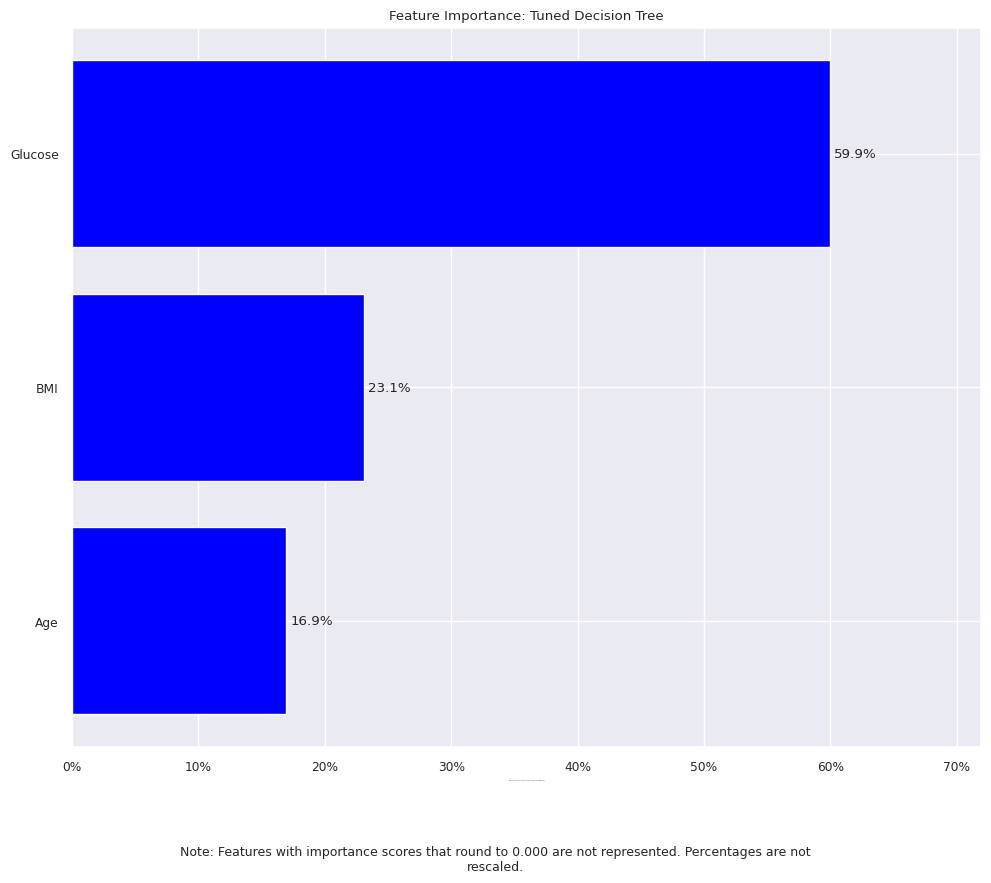

Highest-ranked features in this fitted tree:
- Glucose: 59.9%
- BMI: 23.1%
- Age: 16.9%

Excluded features (importance rounds to 0.000): Pregnancies, D_BP, Skin_Thickness, Insulin, Pedigree

These percentages describe each feature's share of total impurity reduction, not its effect on diabetes risk.


In [60]:
# @title **Visualize feature importance from the tuned decision tree**

import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.ticker import PercentFormatter

tree_classifier = dtree.named_steps["classifier"]
feature_names = dtree.named_steps["imputer"].get_feature_names_out()
importances = tree_classifier.feature_importances_

# Exclude scores that round to 0.000 at three decimal places.
included = np.round(importances, 3) > 0
excluded_features = feature_names[~included].tolist()

excluded_note = (
    "Excluded features (importance rounds to 0.000): "
    + ", ".join(excluded_features)
    if excluded_features
    else "No features were excluded."
)

if included.any():
    shown_names = feature_names[included]
    shown_importances = importances[included]
    indices = np.argsort(shown_importances)

    note = textwrap.fill(
        "Note: Features with importance scores that round to 0.000 "
        "are not represented. Percentages are not rescaled.",
        width=100
    )
    note_lines = len(note.splitlines())
    bottom_margin = 0.6 + 0.18 * note_lines
    figure_height = 8 + bottom_margin

    fig, ax = plt.subplots(figsize=(10, figure_height))

    bars = ax.barh(
        range(len(indices)),
        shown_importances[indices],
        color="blue"
    )

    ax.set_yticks(range(len(indices)))
    ax.set_yticklabels(shown_names[indices])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

    ax.bar_label(
        bars,
        labels=[f"{value:.1%}" for value in shown_importances[indices]],
        padding=3
    )

    ax.set_xlim(0, shown_importances.max() * 1.2)
    ax.set_xlabel("Feature Importance (% of total impurity reduction)")
    ax.set_title("Feature Importance: Tuned Decision Tree")

    fig.text(
        0.5, 0.02,
        note,
        ha="center",
        va="bottom",
        fontsize=9
    )

    plt.tight_layout(
        rect=[0, bottom_margin / figure_height, 1, 1]
    )
    plt.show()

    print("Highest-ranked features in this fitted tree:")
    for index in indices[::-1][:3]:
        print(f"- {shown_names[index]}: {shown_importances[index]:.1%}")

else:
    print("All feature importance scores round to 0.000; no graph displayed.")

print(f"\n{excluded_note}")
print(
    "\nThese percentages describe each feature's share of total "
    "impurity reduction, not its effect on diabetes risk."
)

**Interpreting the tuned decision tree.** Tuning on F2 (Modification 2) picked a smaller tree than the original F1 tuning, with max depth 4 and 5 leaf nodes vs depth 8 and 10 leaves, plus balanced class weights. The training vs test table shows recall of 0.909 on training and 0.827 on test, precision of about 0.56 for both, and test accuracy of 0.714. The gap between training and test is small, so the shallow tree generalizes much better than the unpruned one in the comparison loop (test recall 0.531). The tree only splits on glucose (59.9% of the impurity reduction), BMI (23.1%), and age (16.9%). The other five predictors drop out entirely. That agrees with the inferential results and the correlations, and it makes the tree easy to read as a set of rules. Importance here is about how useful a variable is for the splits, not about cause.

## **Summary of Modifications and Conclusions**

**What I changed and why**

1. **Automated test selection (conditional logic).** A function picks Welch's t-test or Mann-Whitney U for each predictor based on skewness, and applies a Bonferroni correction. Several predictors are heavily skewed, so assuming normal means for all of them wasn't appropriate.
2. **Goal-driven tuning and cutoff (user-defined goal and decision thresholds).** `ANALYSIS_GOAL` decides whether the tree is tuned on F2 or F1 and whether the cutoff targets 80% sensitivity or maximizes Youden's J. For diabetes screening, missing a case costs more than a false alarm, so recall should count more. Setting it to `"balanced"` reproduces the original results exactly.
3. **Automatic class weighting (conditional logic based on the data).** If the smaller class is under 40% of the training data, the logistic regression and random forest use balanced class weights. With 35% diabetes, this raised logistic regression recall from 0.53 to 0.72 without hurting AUC.
4. **Random forest and combined ROC plot (model comparison and visualization).** A third model added to the automated loop, plus one ROC chart for all models.

Smaller cleanup changes include a single settings cell for the seed, alpha, and cutoffs, a fixed seed on the random-sample cell (it used `np.random.seed()` with no value, so it changed every run), a call to `get_metrics_score`, which was defined but never used, and markdown explaining each stage.

**Main findings.** Glucose is the strongest predictor by every measure (correlation, test p-values, tree importance), with BMI and age next. Logistic regression and random forest have the same discrimination (AUC ≈ 0.84), and both beat a single tree. Under the screening setup, logistic regression catches about 77% of test-set diabetes cases, compared with 57% under the original configuration.

**Limitations.** Zeros were treated as missing and filled with training medians. Insulin and skin thickness are missing for a large share of patients, so the imputed values carry a lot of weight. The test set has only 231 patients (81 with diabetes), so the metrics would shift somewhat with a different split. The 0.40 class-share rule and the 1.0 skewness cutoff are judgment calls, not standard values. The population is female, Pima Indian heritage, age 21+, so none of this should be assumed to transfer to other groups. All results are associations, not causes.